# 로컬 VLM 비교 (기능 A·B)

기능 A(게임 스크린샷 → 홍보 문구)와 기능 B(한국어 요청 → 배너용 장면 태그·문구)를 로컬 VLM 하나로 처리하기 위해 후보를 비교한다(10/22 결정). Claude API 결과(02)는 비교용 기준선으로만 쓴다.

| 후보 | 크기 | bf16 가중치(파라미터 × 2바이트) | 고른 사유 |
|---|---|---|---|
| kakaocorp/kanana-1.5-v-3b-instruct | 3.7B | 약 7.4GB | 한국어 태그, 배너 생성(VRAM 13.07GB, 05)과 동시 적재 가능 |
| google/gemma-3-4b-it | 4.3B | 약 8.6GB | 동시 적재 가능, 접근 동의 필요 |
| microsoft/Phi-4-multimodal-instruct | 5.6B | 약 11.2GB | 한국어 태그, MIT 라이선스 |
| Qwen/Qwen3-VL-8B-Instruct | 8.8B | 약 17.6GB | 후보 중 가장 큰 Apache 모델, 배너 생성과는 번갈아 적재 |

크기·태그·라이선스는 02 "검토했던 로컬 후보" 표(10/15, Hugging Face 모델 정보) 기준이다.

- 로드 방식은 모델 카드·transformers 문서 기준이다.
  - Qwen3-VL: 모델 카드 Quickstart(`apply_chat_template`)
  - Gemma 3: transformers 이미지-텍스트 모델(`AutoModelForImageTextToText`)
  - Phi-4-multimodal: 모델 카드가 요구하는 transformers 4.48.2가 아니라 고정된 5.20.1을 쓰므로, transformers 문서(phi4_multimodal)의 기본 지원 방식(`AutoModelForCausalLM` + `vision-lora` 어댑터)으로 로드한다
  - kanana: 모델 카드를 확인하지 못해 `trust_remote_code=True`로 일반 방식 로드를 시도한다
- 모델마다 별도 프로세스에서 실행한다. 로드나 생성이 실패해도 노트북은 남고, 실패 사유가 기록에 남는다.
- 생성은 탐욕적 디코딩(`do_sample=False`)으로 한다. 같은 입력에 같은 출력이 나와야 모델끼리 비교할 수 있다.

## 설정

In [1]:
import json
import os
import random
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw'
OUT_DIR = ROOT / 'outputs' / 'local_vlm'
OUT_DIR.mkdir(parents=True, exist_ok=True)
RECORDS_CSV = OUT_DIR / 'local_vlm_records.csv'
RUNS_CSV = OUT_DIR / 'local_vlm_runs.csv'
CLAUDE_A = ROOT / 'outputs' / 'copy_compare' / 'claude_copy_scored.csv'
CLAUDE_B_CSV = OUT_DIR / 'claude_b_records.csv'

MODELS = {
    'kanana_3b': dict(repo='kakaocorp/kanana-1.5-v-3b-instruct', loader='image_text', trust_remote_code=True),
    'gemma3_4b': dict(repo='google/gemma-3-4b-it', loader='image_text', trust_remote_code=False),
    'phi4_mm': dict(repo='microsoft/Phi-4-multimodal-instruct', loader='causal_lm_phi4', trust_remote_code=False),
    'qwen3vl_8b': dict(repo='Qwen/Qwen3-VL-8B-Instruct', loader='image_text', trust_remote_code=False),
}
MAX_NEW_TOKENS = 512

# 기능 A 입력: 02와 같은 표본(게임마다 5장, seed 0)과 같은 지시문
GAMES = {
    'nai': dict(files=sorted((RAW / 'nai/lora_gen').glob('*_screenshot.png')),
                info='냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임'),
    'x72': dict(files=sorted((RAW / 'pixel_0x72/scenes').glob('x72_scene_*.png')), info='픽셀 아트 던전 탐험 게임'),
    'kaykit': dict(files=sorted((RAW / 'kaykit/renders').glob('kk_*.png')), info='로우폴리 3D 판타지 어드벤처 게임'),
}
rng = random.Random(0)
SAMPLES = [(g, p) for g, d in GAMES.items() for p in rng.sample(d['files'], 5)]
TONE = '밝고 친근한 톤'
SYSTEM_A = '너는 1인 인디게임 개발사의 마케팅 카피라이터다.'
INSTRUCTION_A = '''게임 정보: {info}
요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''

# 기능 B 입력: 사용자가 쓰는 한국어 요청 예시 (게임마다 2개)
B_REQUESTS = [
    ('nai', '여름 바다 배경으로 냥기사 할인 배너 만들어줘. 50% 할인이고 10월 25일부터 11월 3일까지야.'),
    ('nai', '할로윈 분위기로 밤 숲에서 이벤트 배너, 신규 의상 업데이트 알려줘'),
    ('kaykit', '성 앞마당에서 기사가 깃발 든 느낌으로 신규 영웅 업데이트 배너, 버전 1.2, 11월 1일 출시'),
    ('kaykit', '눈 내리는 겨울 마을 배경으로 겨울 이벤트 배너 만들어줘, 30% 할인'),
    ('x72', '금화가 가득한 보물방 배경으로 던전 확장팩 출시 기념 30% 할인 배너, 11월 5일까지'),
    ('x72', '용암 던전 배경으로 보스 레이드 이벤트 배너 만들어줘'),
]
SYSTEM_B = '너는 게임 이벤트 배너 제작을 돕는 도우미다.'
INSTRUCTION_B = '''게임 정보: {info}
요청: {request}

요청을 읽고 이미지 생성용 영어 장면 태그와 배너 문구를 만들어줘.
- scene: 배경과 장면을 묘사하는 영어 태그 5~10개, 쉼표로 구분. 글자·텍스트·로고 관련 태그는 넣지 마.
- title: 배너 제목, 한국어, 20자 이내
- sub: 기간·조건 등 부제, 한국어
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"scene": "tag1, tag2", "title": "제목", "sub": "부제"}}'''

TASKS = [dict(task='A', item=p.name, image=str(p.resolve()), system=SYSTEM_A,
              prompt=INSTRUCTION_A.format(info=GAMES[g]['info'], tone=TONE), game=g) for g, p in SAMPLES]
TASKS += [dict(task='B', item=f'B{i}', image=None, system=SYSTEM_B,
               prompt=INSTRUCTION_B.format(info=GAMES[g]['info'], request=r), game=g, request=r)
          for i, (g, r) in enumerate(B_REQUESTS)]
print(len(SAMPLES), 'A images /', len(B_REQUESTS), 'B requests ×', len(MODELS), 'models')

15 A images / 6 B requests × 4 models


## 접근·디스크 확인

In [4]:
from huggingface_hub import auth_check, snapshot_download
from huggingface_hub.utils import GatedRepoError, RepositoryNotFoundError

for name, m in MODELS.items():
    try:
        auth_check(m['repo'])
        print(f'{name:11s} 접근 가능')
    except GatedRepoError:
        print(f'{name:11s} 접근 동의 필요 → Hugging Face에서 {m["repo"]} 페이지의 동의 버튼을 눌러야 함')
    except RepositoryNotFoundError:
        print(f'{name:11s} 저장소 없음 또는 비공개')
print('disk free', round(shutil.disk_usage(ROOT.resolve()).free / 1024**3, 1), 'GB')

c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


kanana_3b   접근 가능
gemma3_4b   접근 가능
phi4_mm     접근 가능
qwen3vl_8b  접근 가능
disk free 87.0 GB


## 생성 및 측정

- 모델마다 가중치를 먼저 받고(다운로드 시간 기록), 별도 프로세스에서 로드한 뒤 A 15건 + B 6건을 생성한다.
- 호출마다 생성 시간, 입력·출력 토큰 수, 최대 GPU 메모리(`torch.cuda.max_memory_allocated`)를 `local_vlm_records.csv`에 바로 저장한다. 다시 실행하면 성공한 건은 건너뛴다.

In [5]:
CHILD = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoProcessor

a = json.loads(sys.stdin.read())
FIELDS = ['model', 'task', 'item', 'sec', 'in_tokens', 'out_tokens', 'peak_vram_gb', 'load_sec', 'text', 'error']


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()
try:
    trc = a['trust_remote_code']
    proc = AutoProcessor.from_pretrained(a['repo'], trust_remote_code=trc)
    kw = dict(dtype=torch.bfloat16, device_map='cuda')
    if trc:
        kw['trust_remote_code'] = True
    if a['loader'] == 'causal_lm_phi4':
        from transformers import AutoModelForCausalLM
        model = AutoModelForCausalLM.from_pretrained(a['repo'], **kw)
        # transformers 문서(phi4_multimodal): 어댑터 없이는 기본 모델이 제대로 동작하지 않음
        model.load_adapter(a['repo'], adapter_name='vision', device_map='cuda', adapter_kwargs={'subfolder': 'vision-lora'})
        model.set_adapter('vision')
    else:
        from transformers import AutoModelForImageTextToText
        model = AutoModelForImageTextToText.from_pretrained(a['repo'], **kw)
    model.eval()
except Exception as e:
    write(dict(model=a['name'], task='load', error=f'{type(e).__name__}: {e}'[:500]))
    print('LOAD_FAIL', type(e).__name__, str(e)[:300], flush=True)
    sys.exit(0)
load_sec = round(time.perf_counter() - t0, 1)
print('LOADED', a['name'], load_sec, 's', flush=True)

for t in a['tasks']:
    rec = dict(model=a['name'], task=t['task'], item=t['item'], load_sec=load_sec)
    try:
        content = []
        if t['image']:
            content.append({'type': 'image', 'image': Image.open(t['image']).convert('RGB')})
        content.append({'type': 'text', 'text': t['prompt']})
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': content}]
        try:
            inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True,
                                              return_dict=True, return_tensors='pt')
        except Exception:
            # system 역할을 받지 않는 채팅 템플릿이면 지시문을 사용자 메시지 앞에 붙임
            content[-1] = {'type': 'text', 'text': t['system'] + '\n\n' + t['prompt']}
            inputs = proc.apply_chat_template([{'role': 'user', 'content': content}], add_generation_prompt=True,
                                              tokenize=True, return_dict=True, return_tensors='pt')
        inputs = inputs.to(model.device)
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], do_sample=False)
        rec['sec'] = round(time.perf_counter() - t1, 2)
        n_in = inputs['input_ids'].shape[1]
        rec['in_tokens'] = int(n_in)
        rec['out_tokens'] = int(out.shape[1] - n_in)
        rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
        rec['text'] = proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(t['task'], t['item'], rec.get('sec'), 's', rec.get('error', '')[:120], flush=True)
"""


def done_items(name):
    if not RECORDS_CSV.exists():
        return set()
    r = pd.read_csv(RECORDS_CSV, keep_default_na=False, dtype=str)
    return set(r[(r.model == name) & (r.error == '') & (r.task != 'load')].item)


for name, m in MODELS.items():
    # kanana·Phi-4는 transformers 5.x(myenv)에서 로드되지 않아 별도 환경(vlm4x)에서 돌렸다. 실행 셀과 출력은 08_local_vlm_record_vlm4x.ipynb
    if name in ('kanana_3b', 'phi4_mm'):
        print(name, '별도 환경에서 실행 완료(기록 파일) → 건너뜀')
        continue
    todo = [t for t in TASKS if t['item'] not in done_items(name)]
    if not todo:
        print(name, '이미 완료 → 건너뜀')
        continue
    t0 = time.perf_counter()
    try:
        path = snapshot_download(m['repo'])
        dl_sec = round(time.perf_counter() - t0, 1)
        dl_gb = round(sum(f.stat().st_size for f in Path(path).rglob('*') if f.is_file()) / 1024**3, 2)
    except Exception as e:
        print(name, '다운로드 실패', type(e).__name__, str(e)[:200])
        pd.DataFrame([dict(model=name, returncode=None, download_sec=None, download_gb=None, error=f'download {type(e).__name__}')]).to_csv(
            RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8')
        continue
    arg = json.dumps(dict(name=name, repo=m['repo'], loader=m['loader'], trust_remote_code=m['trust_remote_code'],
                          max_new_tokens=MAX_NEW_TOKENS, out=str(RECORDS_CSV.resolve()), tasks=todo))
    p = subprocess.run([sys.executable, '-c', CHILD], input=arg, capture_output=True, text=True, encoding='utf-8',
                       errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    print(p.stdout[-3000:])
    if p.returncode != 0:
        print(p.stderr[-2000:])
    pd.DataFrame([dict(model=name, returncode=p.returncode, download_sec=dl_sec, download_gb=dl_gb,
                       error='' if p.returncode == 0 else p.stderr[-300:])]).to_csv(
        RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False, encoding='utf-8')

kanana_3b 별도 환경에서 실행 완료(기록 파일) → 건너뜀
gemma3_4b 이미 완료 → 건너뜀
phi4_mm 별도 환경에서 실행 완료(기록 파일) → 건너뜀
qwen3vl_8b 이미 완료 → 건너뜀


## Claude 기준선 (기능 B)

기능 A의 Claude 결과는 02에 있다. 기능 B는 02에 없으므로 같은 요청 6건을 Claude 3개 모델로 한 번씩 돌려 기준선을 만든다. 02 실측 1회 비용(Haiku 약 0.0003달러, Sonnet 약 0.0057달러, Opus 약 0.0128달러, `claude_copy_summary.csv`)으로 보면 18회에 약 0.1달러다. `RUN_CLAUDE_B = False`로 두면 건너뛴다.

In [6]:
RUN_CLAUDE_B = True
CLAUDE_MODELS = ['claude-haiku-5-5', 'claude-sonnet-5-5', 'claude-opus-5-5']

if RUN_CLAUDE_B:
    import anthropic
    from dotenv import load_dotenv

    load_dotenv(ROOT / '.env')
    client = anthropic.Anthropic()
    done = set()
    if CLAUDE_B_CSV.exists():
        prev = pd.read_csv(CLAUDE_B_CSV, keep_default_na=False, dtype=str)
        done = set(zip(prev.model, prev.item))
    for t in [t for t in TASKS if t['task'] == 'B']:
        for cm in CLAUDE_MODELS:
            if (cm, t['item']) in done:
                continue
            rec = dict(model=cm, task='B', item=t['item'], sec=None, in_tokens=None, out_tokens=None, text='', error='')
            try:
                t0 = time.perf_counter()
                r = client.messages.create(model=cm, max_tokens=MAX_NEW_TOKENS * 4, system=t['system'],
                                           messages=[{'role': 'user', 'content': t['prompt']}])
                rec['sec'] = round(time.perf_counter() - t0, 2)
                rec['in_tokens'], rec['out_tokens'] = r.usage.input_tokens, r.usage.output_tokens
                rec['text'] = ''.join(b.text for b in r.content if b.type == 'text')
            except Exception as e:
                rec['error'] = f'{type(e).__name__}: {e}'[:300]
            pd.DataFrame([rec]).to_csv(CLAUDE_B_CSV, mode='a', header=not CLAUDE_B_CSV.exists(), index=False, encoding='utf-8')
            print(cm, t['item'], rec['sec'], rec['error'][:100])

## 지표 계산

- 기능 A (02와 같은 지표): JSON으로 읽히는지, 형식 준수(스토어 2문장 + SNS 1문장), 한국어 비율, 생성 시간
- 기능 B
  - JSON으로 읽히는지(`scene`, `title`, `sub`)
  - 장면 태그 영어 비율: 태그의 글자(한글·영문) 중 영문 비율. 이미지 모델(animagine_xl4)이 영어 태그를 쓰기 때문이다
  - 태그 수 5~10개 준수
  - 제목 20자 이내 준수
  - 숫자 보존: 요청에 있는 숫자(할인율, 날짜, 버전)가 제목·부제에 모두 남아 있는지
- Claude는 기준선으로 함께 표시한다(A는 02 결과에서 본 비교 조건 `TONE`·게임 정보 사용만).

In [7]:
def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음 (02와 같은 기준)
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def korean_ratio(s):
    hangul = len(re.findall(r'[가-힣]', s))
    letters = hangul + len(re.findall(r'[A-Za-z一-鿿]', s))
    return hangul / letters if letters else 0.0


def score_a(text):
    d = parse_json(text)
    ok = bool(d) and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)
    if not ok:
        return dict(json_ok=False, format_ok=False, ko_ratio=np.nan)
    store = ' '.join(map(str, d['store']))
    fmt = sum(n_sentences(str(x)) for x in d['store']) == 2 and n_sentences(d['sns']) == 1
    return dict(json_ok=True, format_ok=fmt, ko_ratio=korean_ratio(store + ' ' + d['sns']))


REQ = {t['item']: t['request'] for t in TASKS if t['task'] == 'B'}


def score_b(text, item):
    d = parse_json(text)
    ok = bool(d) and all(isinstance(d.get(k), str) for k in ['scene', 'title', 'sub'])
    if not ok:
        return dict(json_ok=False, scene_en_ratio=np.nan, tags_ok=False, title_ok=False, numbers_kept=np.nan)
    tags = [x.strip() for x in d['scene'].split(',') if x.strip()]
    letters = re.findall(r'[A-Za-z가-힣]', d['scene'])
    en = len(re.findall(r'[A-Za-z]', d['scene'])) / len(letters) if letters else 0.0
    nums = re.findall(r'\d+(?:\.\d+)?', REQ[item])
    kept = np.mean([n in d['title'] + ' ' + d['sub'] for n in nums]) if nums else np.nan
    return dict(json_ok=True, scene_en_ratio=en, tags_ok=5 <= len(tags) <= 10, title_ok=len(d['title']) <= 20,
                numbers_kept=kept)


loc = pd.read_csv(RECORDS_CSV, keep_default_na=False, dtype=str)
load_fail = loc[loc.task == 'load'][['model', 'error']]
loc = loc[(loc.task != 'load') & (loc.error == '')].drop_duplicates(['model', 'item'], keep='last').copy()
for c in ['sec', 'in_tokens', 'out_tokens', 'peak_vram_gb', 'load_sec']:
    loc[c] = pd.to_numeric(loc[c])
loc['source'] = 'local'

cla = pd.read_csv(CLAUDE_A, keep_default_na=False)
cla = cla[(cla.tone == TONE) & (cla.use_info.astype(str) == 'True')]
cla = cla.assign(task='A', item=cla.file, source='Claude')[['model', 'task', 'item', 'sec', 'text', 'source']]
frames = [loc, cla]
if CLAUDE_B_CSV.exists():
    cb = pd.read_csv(CLAUDE_B_CSV, keep_default_na=False)
    frames.append(cb[cb.error == ''].assign(source='Claude')[['model', 'task', 'item', 'sec', 'text', 'source']])
allr = pd.concat(frames, ignore_index=True)
allr['sec'] = pd.to_numeric(allr.sec)

A = allr[allr.task == 'A'].copy()
A = pd.concat([A.reset_index(drop=True), pd.DataFrame([score_a(t) for t in A.text])], axis=1)
B = allr[allr.task == 'B'].copy()
B = pd.concat([B.reset_index(drop=True), pd.DataFrame([score_b(t, i) for t, i in zip(B.text, B.item)])], axis=1)
A.to_csv(OUT_DIR / 'scored_A.csv', index=False, encoding='utf-8-sig')
B.to_csv(OUT_DIR / 'scored_B.csv', index=False, encoding='utf-8-sig')

ORDER = list(MODELS) + CLAUDE_MODELS
sumA = A.groupby('model').agg(n=('item', 'size'), json_ok=('json_ok', 'mean'), format_ok=('format_ok', 'mean'),
                              ko_ratio=('ko_ratio', 'mean'), sec=('sec', 'mean')).reindex(ORDER)
sumB = B.groupby('model').agg(n=('item', 'size'), json_ok=('json_ok', 'mean'), scene_en_ratio=('scene_en_ratio', 'mean'),
                              tags_ok=('tags_ok', 'mean'), title_ok=('title_ok', 'mean'),
                              numbers_kept=('numbers_kept', 'mean'), sec=('sec', 'mean')).reindex(ORDER)
res = loc.groupby('model').agg(load_sec=('load_sec', 'first'), peak_vram_gb=('peak_vram_gb', 'max')).reindex(list(MODELS))
if RUNS_CSV.exists():
    runs = pd.read_csv(RUNS_CSV).drop_duplicates('model', keep='last').set_index('model')
    res = res.join(runs[['download_sec', 'download_gb']])
print('로드 실패:')
display(load_fail)
display(sumA.round(3))
display(sumB.round(3))
display(res.round(2))
sumA.to_csv(OUT_DIR / 'summary_A.csv', encoding='utf-8-sig')
sumB.to_csv(OUT_DIR / 'summary_B.csv', encoding='utf-8-sig')

로드 실패:


,model,error
0,kanana_3b,ImportError: This modeling file requires the f...
1,kanana_3b,ImportError: This modeling file requires the f...
2,phi4_mm,ValueError: The repository microsoft/Phi-4-mul...
24,kanana_3b,ImportError: This modeling file requires the f...
46,phi4_mm,ValueError: The repository microsoft/Phi-4-mul...
47,kanana_3b,ValueError: Unrecognized configuration class <...
48,phi4_mm,ValueError: The repository microsoft/Phi-4-mul...
49,kanana_3b,ValueError: Unrecognized configuration class <...
50,phi4_mm,ValueError: The repository microsoft/Phi-4-mul...
51,kanana_3b,ValueError: Unrecognized configuration class <...


,n,json_ok,format_ok,ko_ratio,sec
model,,,,,
kanana_3b,NaN,NaN,NaN,NaN,NaN
gemma3_4b,15.0,1.0,0.200,0.998,9.681
phi4_mm,NaN,NaN,NaN,NaN,NaN
qwen3vl_8b,15.0,1.0,0.733,0.995,38.166
claude-haiku-5-5,15.0,1.0,0.667,0.996,3.560
claude-sonnet-5-5,15.0,1.0,0.467,0.997,3.155
claude-opus-5-5,15.0,1.0,0.800,0.999,5.729


,n,json_ok,scene_en_ratio,tags_ok,title_ok,numbers_kept,sec
model,,,,,,,
kanana_3b,6,1.000,1.0,1.000,1.000,1.000,3.722
gemma3_4b,6,1.000,1.0,1.000,1.000,0.950,6.780
phi4_mm,6,0.833,1.0,0.833,0.500,0.817,10.460
qwen3vl_8b,6,1.000,1.0,1.000,1.000,1.000,4.430
claude-haiku-5-5,6,1.000,1.0,1.000,0.667,1.000,2.025
claude-sonnet-5-5,6,1.000,1.0,1.000,0.667,1.000,1.873
claude-opus-5-5,6,1.000,1.0,1.000,1.000,1.000,5.605


,load_sec,peak_vram_gb,download_sec,download_gb
model,,,,
kanana_3b,11.5,6.87,0.2,6.85
gemma3_4b,10.3,8.14,97.0,8.05
phi4_mm,14.5,11.24,0.3,11.99
qwen3vl_8b,19.1,16.73,137.6,16.34


## 시각화

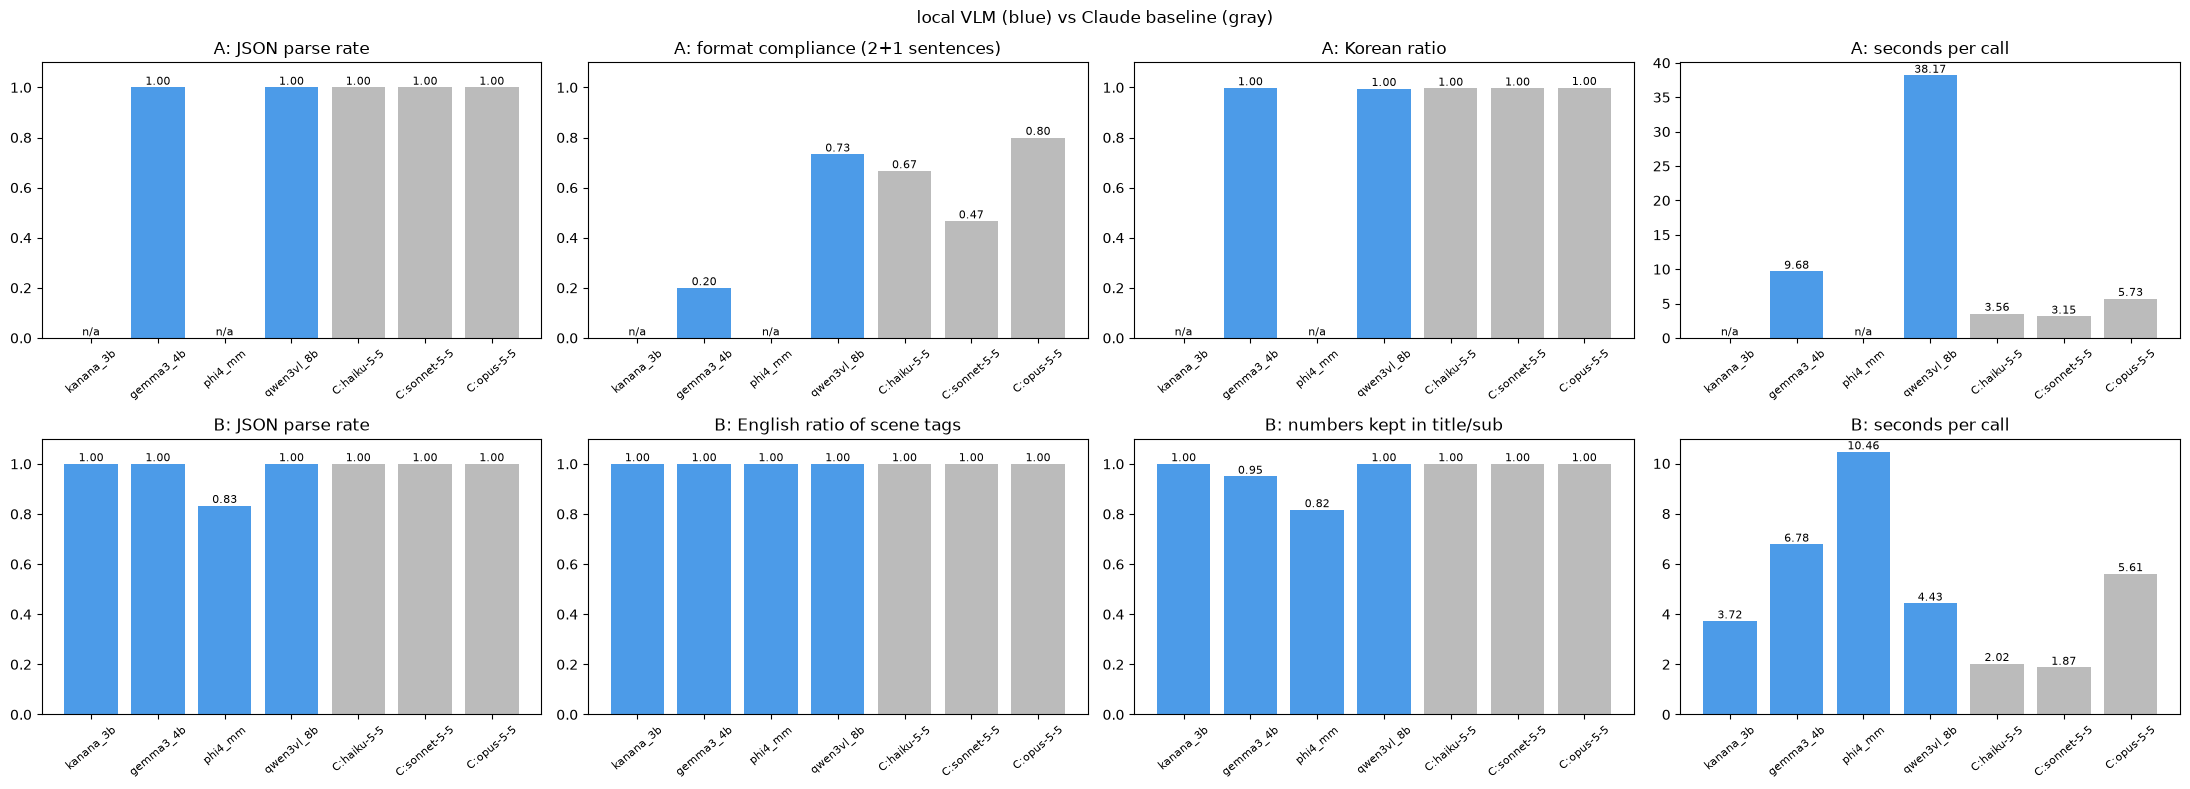

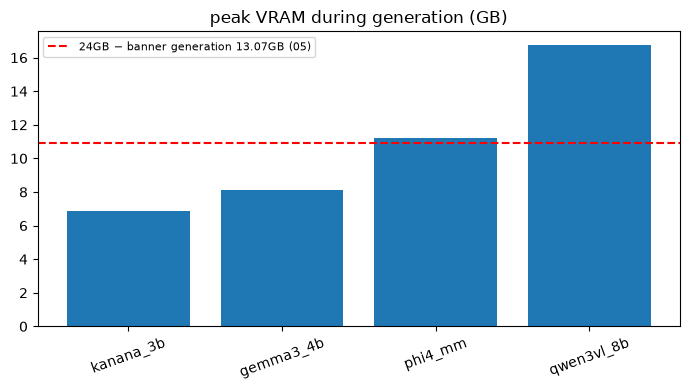

In [8]:
short = {m: m.replace('claude-', 'C:') for m in ORDER}
colors = ['#4C9BE8' if m in MODELS else '#BBBBBB' for m in ORDER]
x = np.arange(len(ORDER))
fig, axes = plt.subplots(2, 4, figsize=(22, 8))
panels = [(sumA, 'json_ok', 'A: JSON parse rate'), (sumA, 'format_ok', 'A: format compliance (2+1 sentences)'),
          (sumA, 'ko_ratio', 'A: Korean ratio'), (sumA, 'sec', 'A: seconds per call'),
          (sumB, 'json_ok', 'B: JSON parse rate'), (sumB, 'scene_en_ratio', 'B: English ratio of scene tags'),
          (sumB, 'numbers_kept', 'B: numbers kept in title/sub'), (sumB, 'sec', 'B: seconds per call')]
for ax, (df, col, title) in zip(axes.ravel(), panels):
    v = df[col].reindex(ORDER).values.astype(float)
    ax.bar(x, np.nan_to_num(v), color=colors)
    for i, val in enumerate(v):
        ax.text(i, 0 if np.isnan(val) else val, 'n/a' if np.isnan(val) else f'{val:.2f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x, [short[m] for m in ORDER], rotation=40, fontsize=8)
    ax.set_title(title)
    if col != 'sec':
        ax.set_ylim(0, 1.1)
plt.suptitle('local VLM (blue) vs Claude baseline (gray)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'local_vlm_compare.png', dpi=90)
plt.show()

if len(res.dropna(how='all')):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(res.index, res.peak_vram_gb.fillna(0))
    ax.axhline(24 - 13.07, color='red', linestyle='--', label='24GB − banner generation 13.07GB (05)')
    ax.set_title('peak VRAM during generation (GB)')
    ax.tick_params(axis='x', rotation=20)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(OUT_DIR / 'local_vlm_vram.png', dpi=90)
    plt.show()

## 출력 예시

In [9]:
pd.set_option('display.max_colwidth', 300)
first_a = SAMPLES[0][1].name
display(A[A['item'] == first_a][['model', 'json_ok', 'format_ok', 'text']])
display(B[B['item'] == 'B0'][['model', 'json_ok', 'numbers_kept', 'text']])

,model,json_ok,format_ok,text
0,qwen3vl_8b,True,True,"{""store"": [""검은 고양이 기사가 모험을 떠나는 귀여운 2D 어드벤처 게임!"", ""사냥보다는 친구를 사냥하는, 따뜻한 마음의 여정을 경험해보세요.""], ""sns"": ""냥기사의 여행, 고양이 기사가 빛나는 모험을 시작합니다! 🐱""}"
15,gemma3_4b,True,False,"```json\n{\n ""store"": [""귀여운 검은 고양이 기사, 냥기사의 특별한 여행을 시작하세요! 흥미진진한 모험과 깜찍한 요소가 가득한 2D 횡스크롤 어드벤처 게임입니다."", ""친구들과 함께 즐기기에도 딱 좋은, 스트레스 해소에 최고인 게임! 지금 바로 다운로드하고 냥기사의 모험을 함께 떠나세요.""],\n ""sns"": ""귀여운 냥기사, 어디로 떠날까요? 🐾""\n}\n```"
30,claude-haiku-5-5,True,True,"{""store"": [""빨간 모자를 쓴 검은 고양이 기사가 돌담 마을과 초록 들판을 누비는 2D 횡스크롤 모험, 냥기사의 여행이 시작됩니다!"", ""귀여운 토끼 친구들과 마주치며 용감하게 길을 떠나는 고양이 기사와 함께, 따뜻하고 아기자기한 세계를 탐험해 보세요.""], ""sns"": ""빨간 모자 쓴 검은 고양이 기사가 떠나는 모험, 냥기사의 여행과 함께 오늘도 귀여운 모험을 떠나볼까요? 🐾⚔️""}"
31,claude-sonnet-5-5,True,False,"{""store"": [""빨간 모자를 눌러쓴 검은 고양이 기사와 함께 이끼 낀 오래된 성터를 누비며 숨겨진 비밀을 찾아 떠나는 2D 횡스크롤 어드벤처 <냥기사의 여행>입니다."", ""손그림 같은 따뜻한 풍경 속에서 귀여운 토끼 친구들을 만나고 작은 모험을 하나씩 이겨 내며, 포근하고 즐거운 여정을 느껴 보세요.""], ""sns"": ""빨간 모자 쓴 냥기사와 함께 폭신폭신 모험을 떠나요 🐱🎩 <냥기사의 여행>에서 귀여운 친구들이 기다리고 있어요! #냥기사의여행 #인디게임""}"
32,claude-opus-5-5,True,True,"{""store"": [""빨간 모자와 망토를 두른 작은 검은 고양이 기사가 이끼 낀 고성의 폐허 속으로 씩씩하게 모험을 떠납니다!"", ""풀숲에 숨은 새하얀 토끼 친구와 오래된 돌벽 너머의 비밀을 찾아 따뜻하고 귀여운 2D 횡스크롤 여행을 함께 즐겨보세요.""], ""sns"": ""빨간 모자 냥기사가 고성 폐허에서 새하얀 토끼를 만났어요, 이 귀여운 모험에 함께 떠나볼까요? 🐾""}"


,model,json_ok,numbers_kept,text
0,qwen3vl_8b,True,1.0,"{""scene"": ""summer beach, sunset ocean, palm trees, sandy shore, gentle waves"", ""title"": ""냥기사의 여행 50% 할인"", ""sub"": ""10월 25일 ~ 11월 3일""}"
6,gemma3_4b,True,0.8,"```json\n{""scene"": ""summer beach, blue ocean, sandy shore, cute cat knight, adventure, treasure chest, sunny day, vibrant colors, 2D art, game screenshot"", ""title"": ""냥기사 여름 특가"", ""sub"": ""7월 25일 ~ 11월 3일, 50% 할인!""}\n```"
12,kanana_3b,True,1.0,"```json\n{\n ""scene"": ""summer beach, ocean waves, sun shining, clear blue sky, tropical island"",\n ""title"": ""냥기사 여름 할인"",\n ""sub"": ""50% 할인! 10월 25일 ~ 11월 3일""\n}\n```"
18,phi4_mm,True,0.6,"{""scene"": ""Summer Sea, Iceberg, Ninja Wolf, Sale, October 25th to November 3rd"", ""title"": ""10% OFF - Cool Sale!"", ""sub"": ""Loyalty Discount, October 25th to November 3rd""}"
24,claude-haiku-5-5,True,1.0,"{""scene"": ""black cat knight, summer beach, ocean waves, sunny sky, sandy shore, bright sunlight, sparkling water, tropical sea, 2D side-scrolling game style"", ""title"": ""냥기사 여름 바다 50% 할인"", ""sub"": ""10월 25일 ~ 11월 3일까지 50% 할인""}"
25,claude-sonnet-5-5,True,1.0,"{""scene"": ""summer beach, sparkling blue ocean, black cat knight, small silver armor, sandy shore, palm trees, bright sunny sky, seashells and starfish, 2D side-scrolling game art"", ""title"": ""냥기사의 여름 바다 대모험 50% 할인"", ""sub"": ""10월 25일 ~ 11월 3일 | 냥기사의 여행 전 상품 50% 할인""}"
26,claude-opus-5-5,True,1.0,"{""scene"": ""black cat knight, summer beach, ocean waves, bright blue sky, sunny day, palm trees, white sand, seashells, 2D side-scrolling game art, vibrant colors"", ""title"": ""냥기사의 여행 50% 대할인"", ""sub"": ""10월 25일 ~ 11월 3일 기간 한정""}"


## 문구 규칙 적용 (10/22 수정)

위 결과는 규칙 적용 전 지시문의 기준선으로 남긴다. 02 Claude 문구 45개에서 "모험" 44, "떠나" 44, "~보세요" 43, "함께" 41, "귀여운" 33개가 반복돼(양산형 광고 문구), 기능 A 지시문에 다음 규칙을 넣고 다시 비교한다(Notion A 페이지 "문구 규칙 확정 (10/22)").

1. 사용자 입력(판매 포인트·꼭 넣을 문구)을 최우선으로 반영하고, 꼭 넣을 문구는 글자 그대로 넣는다.
2. 게임 기본 판매 포인트는 사용자 입력이 없거나 부족할 때만 쓴다. 내용은 각 게임 데이터 파일에 있는 요소로만 만들었다.
3. 금지 ① 판촉 표현: 사용자 입력에 없으면 할인·특가·무료·이벤트·출시·사전예약·선물·가격·기간 숫자를 쓰지 않는다. 스크린샷만으로는 사실이 아닌 약속이 되기 때문이다.
4. 금지 ② 상투 구절: 모험을 떠나, 떠나보세요, 떠나볼까요, 함께 떠나, 기다리고 있어요, 귀여운 친구들 ("지금 바로"는 허용)
5. 이미지에 보이는 구체적인 요소(색·사물·장소·행동)를 1개 이상 넣는다.

조건은 같은 이미지 15장 × (사용자 입력 없음 / 있음) = 30건이다. 기능 B는 이번 수정 대상이 아니라 다시 돌리지 않는다.

이번 섹션에서 함께 처리한 것
- kanana: 첫 실행에서 `einops`가 없어 로드 실패 → 설치 후 재시도
- Phi-4-multimodal: 기본 지원 방식 로드 실패("contains custom code which must be executed") → 모델 카드 방식(`trust_remote_code=True`, 프롬프트 `<|user|><|image_1|>…<|end|><|assistant|>`)으로 한 번 시도. 모델 카드는 transformers 4.48.2 기준이라 실패할 수 있고, 실패하면 후보에서 뺀다. 모델 카드 예시의 flash_attention_2 대신 `eager`를 쓴다(Windows에 flash-attn 미설치).
- gemma-3-4b: Hugging Face에서 접근 동의 후 재시도
- 디스크 확인: 남은 공간이 63GB라 Hugging Face 캐시 사용량을 먼저 본다.

### 디스크·캐시 확인

,repo,GB,last_used
0,Qwen/Qwen3-VL-8B-Instruct,16.34,10-22 10:45
1,microsoft/Phi-4-multimodal-instruct,11.99,10-22 10:42
2,google/gemma-3-4b-it,8.05,10-22 11:09
3,h94/IP-Adapter,7.53,10-19 12:32
4,kakaocorp/kanana-1.5-v-3b-instruct,6.85,10-22 10:40
5,cagliostrolab/animagine-xl-4.0,6.46,10-22 10:07
6,nlpai-lab/KURE-v1,6.39,09-09 06:25
7,cagliostrolab/animagine-xl-4.0-zero,6.31,10-21 18:15
8,Qwen/Qwen3-8B-AWQ,5.69,09-09 12:05
9,Kwai-Kolors/Kolors-IP-Adapter-Plus,3.67,10-19 19:16


HF 캐시 합계 91.8 GB | 디스크 남은 공간 87.0 GB


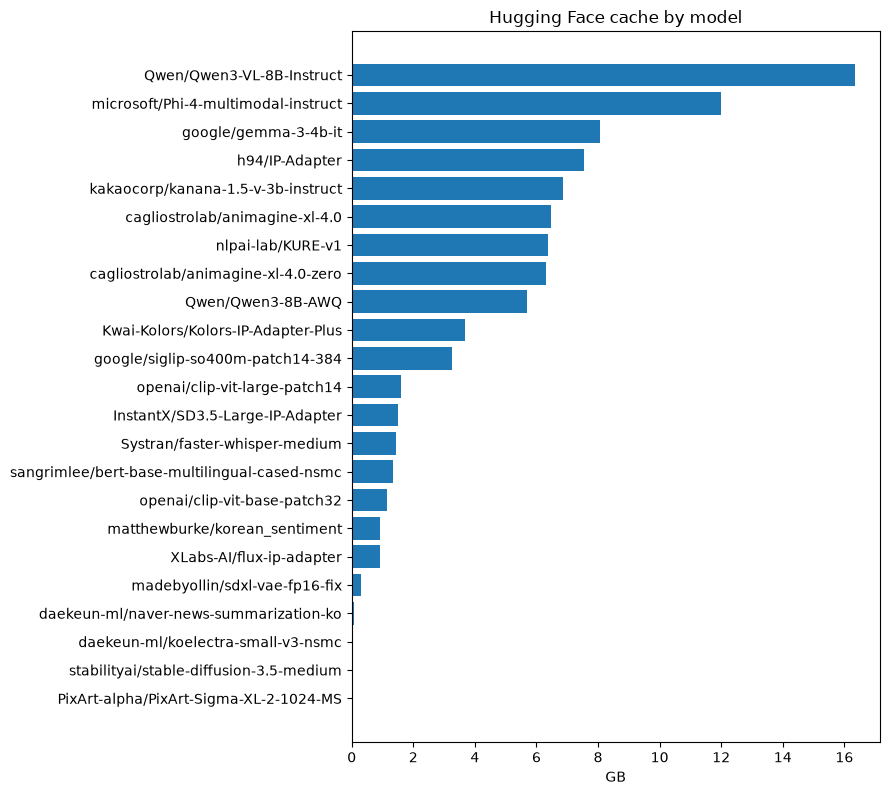

In [10]:
import shutil
from datetime import datetime

from huggingface_hub import scan_cache_dir

info = scan_cache_dir()
cache = pd.DataFrame([{'repo': r.repo_id, 'GB': round(r.size_on_disk / 1024**3, 2),
                       'last_used': datetime.fromtimestamp(r.last_accessed).strftime('%m-%d %H:%M')}
                      for r in info.repos]).sort_values('GB', ascending=False).reset_index(drop=True)
display(cache)
FREE_GB = round(shutil.disk_usage(ROOT.resolve()).free / 1024**3, 1)
print('HF 캐시 합계', round(info.size_on_disk / 1024**3, 1), 'GB | 디스크 남은 공간', FREE_GB, 'GB')

fig, ax = plt.subplots(figsize=(9, max(3, 0.35 * len(cache))))
ax.barh(cache.repo[::-1], cache.GB[::-1])
ax.set_xlabel('GB')
ax.set_title('Hugging Face cache by model')
plt.tight_layout()
plt.show()

### 규칙 적용 지시문

In [3]:
RECORDS_V2 = OUT_DIR / 'local_vlm_records_v2.csv'
RUNS_V2 = OUT_DIR / 'local_vlm_runs_v2.csv'
# 남은 디스크가 이보다 적으면 새 모델을 받지 않음 (gemma-3-4b bf16 가중치 약 8.6GB + 여유)
MIN_FREE_GB = 15

MODELS_V2 = {
    'kanana_3b': dict(repo='kakaocorp/kanana-1.5-v-3b-instruct', loader='image_text', trust_remote_code=True),
    'gemma3_4b': dict(repo='google/gemma-3-4b-it', loader='image_text', trust_remote_code=False),
    'phi4_mm': dict(repo='microsoft/Phi-4-multimodal-instruct', loader='phi4_remote', trust_remote_code=True),
    'qwen3vl_8b': dict(repo='Qwen/Qwen3-VL-8B-Instruct', loader='image_text', trust_remote_code=False),
}

# 게임 기본 판매 포인트 (각 게임 데이터 파일에 있는 요소만 사용)
GAME_POINTS = {
    'nai': ['빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션', '개 기사·부엉이 마법사·토끼 상인 동료',
            '떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지', '동화책 같은 손그림 색감'],
    'x72': ['위에서 내려다보는 16비트 픽셀 던전', '기사·엘프·마법사·드워프 중 골라 플레이',
            '오크·해골·좀비·네크로맨서 등 몬스터', '금화·물약·보물상자(미믹 포함) 수집'],
    'kaykit': ['바바리안·기사·마법사·로그 등 5명의 로우폴리 영웅', '한손·양손 무기, 석궁, 지팡이를 쓰는 전투',
               '회피·막기·연속 공격 액션'],
}
# 사용자 입력 예시 (게임마다 1개). 냥기사는 판촉 표현이 사용자 입력에 있을 때 허용되는지 보려고 할인 문구를 넣음
USER_POINTS = {
    'nai': dict(points='11월 업데이트로 신규 동료 추가', must='11월 업데이트 기념 30% 할인'),
    'x72': dict(points='4인 로컬 협동 플레이 지원', must='스팀 찜하기'),
    'kaykit': dict(points='영웅마다 다른 전용 스킬', must='신규 영웅 로그 추가'),
}
BANNED_PROMO = ['할인', '특가', '무료', '이벤트', '출시', '사전예약', '선물']
BANNED_CLICHE = ['모험을 떠나', '떠나보세요', '떠나볼까요', '함께 떠나', '기다리고 있어요', '귀여운 친구들']

INSTRUCTION_A2 = '''게임 정보: {info}
{user_block}
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
{points}
요청 사항: {tone}

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: {cliche}
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{{"store": ["문장1", "문장2"], "sns": "문장"}}'''


def user_block(g, cond):
    if cond == 'no_input':
        return '사용자 입력: 없음'
    u = USER_POINTS[g]
    return f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\""


TASKS_V2 = []
for cond in ['no_input', 'user_input']:
    for g, p in SAMPLES:
        TASKS_V2.append(dict(task='A2', item=f'{p.name}|{cond}', image=str(p.resolve()), system=SYSTEM_A, game=g, cond=cond,
                             prompt=INSTRUCTION_A2.format(info=GAMES[g]['info'], user_block=user_block(g, cond),
                                                          points='\n'.join('- ' + x for x in GAME_POINTS[g]),
                                                          tone=TONE, cliche=', '.join(BANNED_CLICHE))))
print(len(TASKS_V2), 'tasks')
print(TASKS_V2[len(SAMPLES)]['prompt'])

30 tasks
게임 정보: 냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임
사용자 입력 (최우선): 판매 포인트: 11월 업데이트로 신규 동료 추가 / 꼭 넣을 문구: "11월 업데이트 기념 30% 할인"
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
- 빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션
- 개 기사·부엉이 마법사·토끼 상인 동료
- 떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지
- 동화책 같은 손그림 색감
요청 사항: 밝고 친근한 톤

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: 모험을 떠나, 떠나보세요, 떠나볼까요, 함께 떠나, 기다리고 있어요, 귀여운 친구들
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{"store": ["문장1", "문장2"], "sns": "문장"}


### 생성 및 측정 (규칙 적용)

위 "생성 및 측정"과 같은 방식(모델별 별도 프로세스, 탐욕적 디코딩, 호출마다 저장·이어서 실행)이고, Phi-4 모델 카드 방식 로드가 추가됐다. 결과는 `local_vlm_records_v2.csv`에 저장한다.

In [12]:
CHILD_V2 = CHILD.replace(
    """    if a['loader'] == 'causal_lm_phi4':""",
    """    if a['loader'] == 'phi4_remote':
        from transformers import AutoModelForCausalLM, GenerationConfig
        # 모델 카드 방식. Windows에 flash-attn이 없어 eager 사용 (모델 카드: Ampere 미만이면 eager로 바꾸라고 안내)
        model = AutoModelForCausalLM.from_pretrained(a['repo'], trust_remote_code=True, dtype=torch.bfloat16,
                                                     device_map='cuda', _attn_implementation='eager')
        GEN_CFG = GenerationConfig.from_pretrained(a['repo'])
    elif a['loader'] == 'causal_lm_phi4':""").replace(
    """        content = []""",
    """        if a['loader'] == 'phi4_remote':
            # 모델 카드 프롬프트 형식: <|user|><|image_1|>질문<|end|><|assistant|>
            # 기능 B는 이미지가 없어 이미지 자리표시와 images 인자를 빼고 글만 넣음
            img_tag = '<|image_1|>' if t['image'] else ''
            text = '<|user|>' + img_tag + t['system'] + '\\n\\n' + t['prompt'] + '<|end|><|assistant|>'
            if t['image']:
                inputs = proc(text=text, images=Image.open(t['image']).convert('RGB'), return_tensors='pt').to('cuda')
            else:
                inputs = proc(text=text, return_tensors='pt').to('cuda')
            torch.cuda.reset_peak_memory_stats()
            t1 = time.perf_counter()
            with torch.no_grad():
                out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], generation_config=GEN_CFG, do_sample=False)
            rec['sec'] = round(time.perf_counter() - t1, 2)
            n_in = inputs['input_ids'].shape[1]
            rec['in_tokens'], rec['out_tokens'] = int(n_in), int(out.shape[1] - n_in)
            rec['peak_vram_gb'] = round(torch.cuda.max_memory_allocated() / 1024**3, 2)
            rec['text'] = proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]
            write(rec)
            print(t['task'], t['item'], rec.get('sec'), 's', flush=True)
            continue
        content = []""")
assert CHILD_V2.count('phi4_remote') == 2, '자식 프로세스 코드 치환 실패'


def done_v2(name):
    if not RECORDS_V2.exists():
        return set()
    r = pd.read_csv(RECORDS_V2, keep_default_na=False, dtype=str)
    return set(r[(r.model == name) & (r.error == '') & (r.task != 'load')].item)


for name, m in MODELS_V2.items():
    # kanana·Phi-4는 transformers 5.x(myenv)에서 로드되지 않아 별도 환경(vlm4x)에서 돌렸다. 실행 셀과 출력은 08_local_vlm_record_vlm4x.ipynb
    if name in ('kanana_3b', 'phi4_mm'):
        print(name, '별도 환경에서 실행 완료(기록 파일) → 건너뜀')
        continue
    todo = [t for t in TASKS_V2 if t['item'] not in done_v2(name)]
    if not todo:
        print(name, '이미 완료 → 건너뜀')
        continue
    free = shutil.disk_usage(ROOT.resolve()).free / 1024**3
    t0 = time.perf_counter()
    try:
        path = snapshot_download(m['repo'])
        dl_sec = round(time.perf_counter() - t0, 1)
    except Exception as e:
        print(name, '다운로드 실패', type(e).__name__, str(e)[:200])
        pd.DataFrame([dict(model=name, returncode=None, download_sec=None, free_gb=round(free, 1),
                           error=f'download {type(e).__name__}')]).to_csv(RUNS_V2, mode='a', header=not RUNS_V2.exists(),
                                                                         index=False, encoding='utf-8')
        continue
    if free < MIN_FREE_GB:
        print(name, f'디스크 남은 공간 {free:.1f}GB < {MIN_FREE_GB}GB → 다음 모델부터는 확인 필요')
    arg = json.dumps(dict(name=name, repo=m['repo'], loader=m['loader'], trust_remote_code=m['trust_remote_code'],
                          max_new_tokens=MAX_NEW_TOKENS, out=str(RECORDS_V2.resolve()), tasks=todo))
    p = subprocess.run([sys.executable, '-c', CHILD_V2], input=arg, capture_output=True, text=True, encoding='utf-8',
                       errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    print(p.stdout[-2000:])
    if p.returncode != 0:
        print(p.stderr[-2000:])
    pd.DataFrame([dict(model=name, returncode=p.returncode, download_sec=dl_sec, free_gb=round(free, 1),
                       error='' if p.returncode == 0 else p.stderr[-300:])]).to_csv(
        RUNS_V2, mode='a', header=not RUNS_V2.exists(), index=False, encoding='utf-8')

kanana_3b 별도 환경에서 실행 완료(기록 파일) → 건너뜀
gemma3_4b 이미 완료 → 건너뜀
phi4_mm 별도 환경에서 실행 완료(기록 파일) → 건너뜀
qwen3vl_8b 이미 완료 → 건너뜀


### 지표 계산 (규칙 적용 전·후)

- 기존 지표: JSON 읽힘, 형식 준수(2+1문장), 한국어 비율, 생성 시간
- 추가 지표
  - 판촉 표현 위반: 사용자 입력에 없는 판촉어(`BANNED_PROMO`)나 퍼센트·날짜 숫자가 출력에 들어간 비율
  - 상투 구절 비율: `BANNED_CLICHE` 중 하나라도 들어간 비율
  - 꼭 넣을 문구 반영률: 사용자 입력 조건에서 "꼭 넣을 문구"가 글자 그대로 들어간 비율 (띄어쓰기까지 같아야 인정하는 엄격한 기준)
- 규칙 적용 전(위 결과, 지시문 v1)과 후(v2)를 같은 그래프에 놓는다. Claude는 v1 기준선만 있다.

In [13]:
def promo_violation(text, allowed_src):
    words = [w for w in BANNED_PROMO if w in text and w not in allowed_src]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', text) if n.replace(' ', '') not in allowed_src.replace(' ', '')]
    return bool(words or nums)


def score_v2(text, game, cond):
    d = parse_json(text)
    base = score_a(text)
    body = (' '.join(map(str, d.get('store', []))) + ' ' + str(d.get('sns', ''))) if d else str(text)
    allowed = ' '.join(USER_POINTS[game].values()) if cond == 'user_input' else ''
    return dict(**base, promo_violation=promo_violation(body, allowed),
                cliche=any(c in body for c in BANNED_CLICHE),
                must_kept=(USER_POINTS[game]['must'] in body) if cond == 'user_input' else np.nan)


GAME_OF = {p.name: g for g, p in SAMPLES}
v2 = pd.read_csv(RECORDS_V2, keep_default_na=False, dtype=str) if RECORDS_V2.exists() else pd.DataFrame(columns=['model', 'task', 'item', 'error'])
v2_fail = v2[v2.task == 'load'][['model', 'error']]
v2 = v2[(v2.task != 'load') & (v2.error == '')].drop_duplicates(['model', 'item'], keep='last').copy()
v2['file'] = v2['item'].str.split('|').str[0]
v2['cond'] = v2['item'].str.split('|').str[1]
v2['sec'] = pd.to_numeric(v2.sec)
v2 = pd.concat([v2.reset_index(drop=True),
                pd.DataFrame([score_v2(t, GAME_OF[f], c) for t, f, c in zip(v2.text, v2.file, v2.cond)])], axis=1)
v2['version'] = 'v2 ' + v2.cond

v1 = A.copy()
v1['file'] = v1['item']
v1 = pd.concat([v1.reset_index(drop=True),
                pd.DataFrame([score_v2(t, GAME_OF.get(f, 'nai'), 'no_input') for t, f in zip(v1.text, v1.file)])[['promo_violation', 'cliche']]], axis=1)
v1['version'] = 'v1 (before rules)'
both = pd.concat([v1, v2], ignore_index=True)
both.to_csv(OUT_DIR / 'scored_A_v1_v2.csv', index=False, encoding='utf-8-sig')
print('로드 실패 (v2):')
display(v2_fail)
summ = both.groupby(['model', 'version']).agg(n=('item', 'size'), json_ok=('json_ok', 'mean'), format_ok=('format_ok', 'mean'),
                                              ko_ratio=('ko_ratio', 'mean'), promo_violation=('promo_violation', 'mean'),
                                              cliche=('cliche', 'mean'), must_kept=('must_kept', 'mean'), sec=('sec', 'mean'))
summ.to_csv(OUT_DIR / 'summary_A_v1_v2.csv', encoding='utf-8-sig')
display(summ.round(3))

로드 실패 (v2):


,model,error
0,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
31,phi4_mm,ImportError: This modeling file requires the following packages that were not found in your environment: backoff. Run `pip install backoff`
62,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
63,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors
64,kanana_3b,ImportError: cannot import name 'VisionRotaryEmbedding' from 'transformers.models.qwen2_vl.modeling_qwen2_vl' (c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\transformers\models\qwen2_vl\modeling_qwen2_vl.py)
65,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors
66,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
67,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors
68,kanana_3b,ValueError: Unrecognized configuration class <class 'transformers_modules.kakaocorp.kanana_hyphen_1_dot_5_hyphen_v_hyphen_3b_hyphen_instruct.2e00ef13ccec2e99459a8eada18a1bfd05bff44b.configuration.KananaVConfig'> for this kind of AutoModel: AutoModelForImageTextToText.\nModel type should be one o...
69,phi4_mm,RuntimeError: Tensor.item() cannot be called on meta tensors


n  json_ok  format_ok  ko_ratio  \
model             version                                               
claude-haiku-5-5  v1 (before rules)  15    1.000      0.667     0.996   
claude-opus-5-5   v1 (before rules)  15    1.000      0.800     0.999   
claude-sonnet-5-5 v1 (before rules)  15    1.000      0.467     0.997   
gemma3_4b         v1 (before rules)  15    1.000      0.200     0.998   
                  v2 no_input        15    1.000      0.733     0.996   
                  v2 user_input      15    1.000      0.200     1.000   
kanana_3b         v2 no_input        15    1.000      0.000     0.993   
                  v2 user_input      15    1.000      0.000     0.996   
phi4_mm           v2 no_input        15    0.933      0.600     0.781   
                  v2 user_input      15    0.867      0.133     0.993   
qwen3vl_8b        v1 (before rules)  15    1.000      0.733     0.995   
                  v2 no_input        15    1.000      1.000     0.995   
                  v2 user_input      15    1.000      0.267     0.998   

                                     promo_violation  cliche must_kept     sec  
model             version                                                       
claude-haiku-5-5  v1 (before rules)            0.000   0.867       NaN   3.560  
claude-opus-5-5   v1 (before rules)            0.000   1.000       NaN   5.729  
claude-sonnet-5-5 v1 (before rules)            0.000   1.000       NaN   3.155  
gemma3_4b         v1 (before rules)            0.067   0.200       NaN   9.681  
                  v2 no_input                  0.000   0.000       NaN   9.097  
                  v2 user_input                0.000   0.000  0.066667  10.136  
kanana_3b         v2 no_input                  0.000   0.733       NaN  10.535  
                  v2 user_input                0.000   0.733       0.6   9.823  
phi4_mm           v2 no_input                  0.000   0.067       NaN  16.527  
                  v2 user_input                0.000   0.000       0.4  19.815  
qwen3vl_8b        v1 (before rules)            0.000   0.467       NaN  38.166  
                  v2 no_input                  0.000   0.067       NaN   8.533  
                  v2 user_input                0.000   0.000       1.0   8.119

### 시각화 (규칙 적용 전·후)

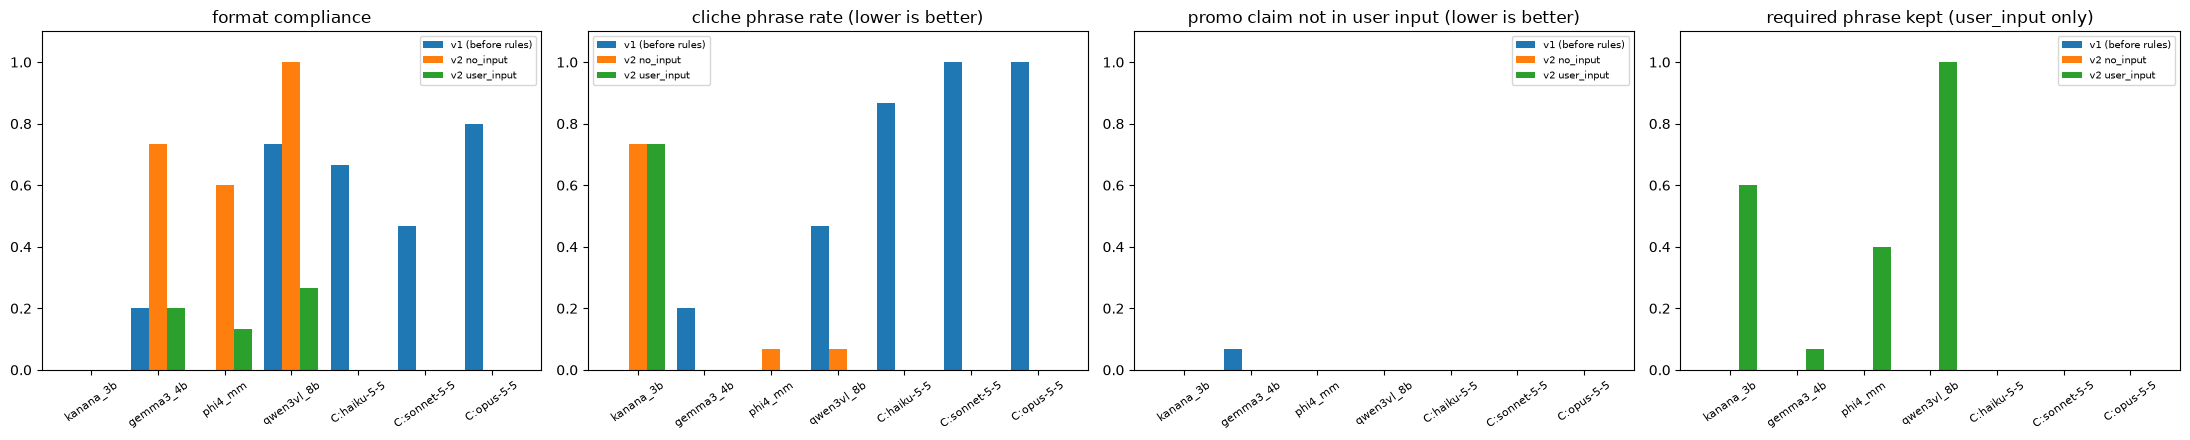

,model,version,cliche,promo_violation,must_kept,text
0,qwen3vl_8b,v1 (before rules),True,False,NaN,"{""store"": [""검은 고양이 기사가 모험을 떠나는 귀여운 2D 어드벤처 게임!"", ""사냥보다는 친구를 사냥하는, 따뜻한 마음의 여정을 경험해보세요.""], ""sns"": ""냥기사의 여행, 고양이 기사가 빛나는 모험을 시작합니다! 🐱""}"
15,gemma3_4b,v1 (before rules),True,False,NaN,"```json\n{\n ""store"": [""귀여운 검은 고양이 기사, 냥기사의 특별한 여행을 시작하세요! 흥미진진한 모험과 깜찍한 요소가 가득한 2D 횡스크롤 어드벤처 게임입니다."", ""친구들과 함께 즐기기에도 딱 좋은, 스트레스 해소에 최고인 게임! 지금 바로 다운로드하고 냥기사의 모험을 함께 떠나세요.""],\n ""sns"": ""귀여운 냥기사, 어디로 떠날까요? 🐾""\n}\n```"
30,claude-haiku-5-5,v1 (before rules),True,False,NaN,"{""store"": [""빨간 모자를 쓴 검은 고양이 기사가 돌담 마을과 초록 들판을 누비는 2D 횡스크롤 모험, 냥기사의 여행이 시작됩니다!"", ""귀여운 토끼 친구들과 마주치며 용감하게 길을 떠나는 고양이 기사와 함께, 따뜻하고 아기자기한 세계를 탐험해 보세요.""], ""sns"": ""빨간 모자 쓴 검은 고양이 기사가 떠나는 모험, 냥기사의 여행과 함께 오늘도 귀여운 모험을 떠나볼까요? 🐾⚔️""}"
31,claude-sonnet-5-5,v1 (before rules),True,False,NaN,"{""store"": [""빨간 모자를 눌러쓴 검은 고양이 기사와 함께 이끼 낀 오래된 성터를 누비며 숨겨진 비밀을 찾아 떠나는 2D 횡스크롤 어드벤처 <냥기사의 여행>입니다."", ""손그림 같은 따뜻한 풍경 속에서 귀여운 토끼 친구들을 만나고 작은 모험을 하나씩 이겨 내며, 포근하고 즐거운 여정을 느껴 보세요.""], ""sns"": ""빨간 모자 쓴 냥기사와 함께 폭신폭신 모험을 떠나요 🐱🎩 <냥기사의 여행>에서 귀여운 친구들이 기다리고 있어요! #냥기사의여행 #인디게임""}"
32,claude-opus-5-5,v1 (before rules),True,False,NaN,"{""store"": [""빨간 모자와 망토를 두른 작은 검은 고양이 기사가 이끼 낀 고성의 폐허 속으로 씩씩하게 모험을 떠납니다!"", ""풀숲에 숨은 새하얀 토끼 친구와 오래된 돌벽 너머의 비밀을 찾아 따뜻하고 귀여운 2D 횡스크롤 여행을 함께 즐겨보세요.""], ""sns"": ""빨간 모자 냥기사가 고성 폐허에서 새하얀 토끼를 만났어요, 이 귀여운 모험에 함께 떠나볼까요? 🐾""}"
75,gemma3_4b,v2 no_input,False,False,NaN,"```json\n{\n ""store"": [""빨간 모자를 쓴 검은 고양이 기사가 칼을 휘두르는 모습이 눈에 띄는 냥기사의 여행."", ""동화 속 풍경을 담은 손그림 스타일과 개 기사, 부엉이 마법사 등 매력적인 동료들이 당신을 기다립니다.""],\n ""sns"": ""숲 속 선술집에서 만난 개 기사와 함께 용감한 모험을 시작하세요!""\n}\n```"
90,gemma3_4b,v2 user_input,False,False,False,"```json\n{\n ""store"": [""빨간 모자를 쓴 검은 고양이 기사가 던진 칼이 빗나가고 있네요! 흥미진진한 횡스크롤 액션 어드벤처 게임, 냥기사의 여행을 지금 바로 만나보세요."", ""동화 속 풍경을 옮겨온 듯한 아름다운 손그림 스테이지와 개 기사, 부엉이 마법사, 토끼 상인 등 다채로운 동료들이 여러분을 기다립니다.""],\n ""sns"": ""11월 업데이트 기념! 냥기사의 여행, 지금 30% 할인 중입니다. 놓치지 마세요!""\n}\n```"
105,qwen3vl_8b,v2 no_input,False,False,NaN,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 그림체의 2D 어드벤처 게임입니다."", ""숲과 성문, 선술집을 넘나드는 스테이지에서 칼과 방패로 싸우는 모험을 즐기세요.""], ""sns"": ""빨간 모자 쓴 고양이 기사가 돌담 위에 앉아 있는, 손그림 같은 아름다운 게임을 만나보세요.""}"
120,qwen3vl_8b,v2 user_input,False,False,True,"{""store"": [""빨간 모자를 쓴 검은 고양이 기사가 돌담 위에 앉아 있는 모습, 풀섬의 풍경이 펼쳐진다."", ""11월 업데이트 기념 30% 할인""], ""sns"": ""빨간 모자와 녹색 망토를 입은 고양이 기사가 풀숲 속 토끼와 마주친다!""}"
135,kanana_3b,v2 no_input,False,False,NaN,"{\n ""store"": [\n ""빨간 모자를 쓴 검은 고양이 기사가 떠다니는 풀섬과 숲을 넘나들며 모험을 떠납니다! 동화책 같은 손그림 색감으로 가득한 2D 횡스크롤 어드벤처 게임, 냥기사의 여행!"",\n ""개 기사, 부엉이 마법사, 토끼 상인과 함께 성문과 선술집을 넘나드는 여정을 즐겨보세요!""\n ],\n ""sns"": ""빨간 모자의 검은 고양이 기사가 떠다니는 풀섬과 숲을 누비는 2D 횡스크롤 어드벤처 게임, 냥기사의 여행! 지금 바로 만나보세요!""\n}"


In [14]:
versions = ['v1 (before rules)', 'v2 no_input', 'v2 user_input']
models_ = [m for m in list(MODELS_V2) + CLAUDE_MODELS if m in summ.index.get_level_values(0)]
x = np.arange(len(models_))
w = 0.27
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, (col, title) in zip(axes, [('format_ok', 'format compliance'), ('cliche', 'cliche phrase rate (lower is better)'),
                                   ('promo_violation', 'promo claim not in user input (lower is better)'),
                                   ('must_kept', 'required phrase kept (user_input only)')]):
    for k, ver in enumerate(versions):
        v = [summ[col].get((m, ver), np.nan) for m in models_]
        ax.bar(x + (k - 1) * w, np.nan_to_num(v), w, label=ver)
    ax.set_xticks(x, [m.replace('claude-', 'C:') for m in models_], rotation=35, fontsize=8)
    ax.set_ylim(0, 1.1)
    ax.set_title(title)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT_DIR / 'local_vlm_rules_compare.png', dpi=90)
plt.show()

pd.set_option('display.max_colwidth', 300)
f0 = SAMPLES[0][1].name
display(both[both.file == f0][['model', 'version', 'cliche', 'promo_violation', 'must_kept', 'text']])

## kanana·Phi-4 실행 (기록 파일로 이동, 10/22)

- kanana-1.5-v-3b와 Phi-4-multimodal은 transformers 5.20.1(myenv)에서 로드되지 않아(kanana `ImportError: VisionRotaryEmbedding`, Phi-4 `RuntimeError: Tensor.item() cannot be called on meta tensors`) Phi-4 모델 카드 requirements 버전(transformers 4.48.2, torch 2.6.0)으로 만든 별도 conda 환경 `vlm4x`에서 돌렸다.
- 결과는 `local_vlm_records.csv`, `local_vlm_records_v2.csv`에 들어 있고, 위 "지표 계산"·"지표 계산 (규칙 적용 전·후)" 표와 그래프에 포함된다.
- 최종 모델을 Qwen3-VL-8B로 정한 뒤 `vlm4x` 환경과 실험용 패키지(timm, omegaconf, backoff, soundfile, einops)를 지웠다. 그래서 그 실행 셀들(패키지 설치 셀 포함)은 출력과 함께 `08_local_vlm_record_vlm4x.ipynb`로 옮겼다. 이 노트북을 전체 실행해도 지운 패키지를 다시 설치하거나 없는 환경을 부르지 않는다.

## 꼭 넣을 문구 처리 방식 비교 (10/22)

규칙 적용 v2에서 Qwen3-VL-8B는 사용자 입력이 있을 때 형식 준수가 0.27이다(`summary_A_v1_v2.csv`). 실패 11건을 보면 꼭 넣을 문구를 문장 뒤에 따로 붙인다(예: `"4인으로 함께 던전을 헤쳐나가보세요. 스팀 찜하기"`). 이 조각이 문장으로 한 번 더 세어져 "정확히 2문장/1문장" 조건이 깨진다. 이를 고치는 두 방식을 같은 조건에서 비교한다.

- ①+② 지시문 보강 + 검증 후 재요청
  - ① 규칙 1에 "꼭 넣을 문구는 sns 문장 안에 문장의 일부로 넣고, 앞이나 뒤에 따로 붙이지 마"와 좋은 예·나쁜 예를 넣는다. 예시는 평가 게임과 겹치지 않게 다른 게임·다른 문구("데모 플레이 가능")로 만들었다.
  - ② 생성 결과를 코드로 검사하고, 실패하면 실패 이유를 모델에 다시 보내 고쳐 쓰게 한다(최대 2번). Instructor 라이브러리의 재요청 방식(검증 실패 오류를 모델에 다시 보내고 `max_retries`까지 재생성)과 같은 구조이고, 2번은 그 문서 예시값(`max_retries=2`)이다.
  - 첫 번째 생성 결과만 따로 집계하면 ① 단독 효과도 볼 수 있다.
- ④ 칸 분리: 모델에는 꼭 넣을 문구를 주지 않고, 꼭 넣을 문구는 별도 칸으로 코드가 붙인다(Google Ads 반응형 광고의 고정(pin) 방식과 같은 구조).
- 기준선: 규칙 적용 v2(사용자 입력 있음) Qwen 결과
- 조건: 모델 Qwen3-VL-8B, 같은 이미지 15장, 같은 사용자 입력(`USER_POINTS`), 탐욕적 디코딩, 별도 프로세스 실행
- 지표
  - `format_ok`: store 2문장 + sns 1문장 (기존 기준과 같은 문장 세기)
  - `must_kept`: 꼭 넣을 문구가 sns에 글자 그대로 있는지 (④는 코드가 붙이므로 항상 1)
  - `integrated`: 꼭 넣을 문구가 따로 떨어진 조각이 아니라 문장 안에 들어갔는지. sns가 1문장이고, 문구를 뺀 나머지에 한글이 8자 이상이며, 문구가 문장부호 바로 뒤 문장 끝이나 문장 첫머리 + 문장부호로 떨어져 있지 않을 때 1 (④는 구조상 0)
  - `promo_violation`, `cliche`: 기존 기준과 같음
  - `attempts`, `sec_total`: 재요청 포함 생성 횟수와 시간
- 결과: `outputs/local_vlm/must_phrase_compare.csv`, `must_phrase_summary.csv`, `must_phrase_compare.png`

In [4]:
MUST_CSV = OUT_DIR / 'must_phrase_compare.csv'
QWEN_REPO = MODELS['qwen3vl_8b']['repo']
# Instructor 문서 reask 예시값
MAX_RETRY = 2

VALIDATOR = r"""
import json, re


def parse_json(text):
    m = re.search(r'\{.*\}', str(text), re.S)
    try:
        d = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        d = None
    return d if isinstance(d, dict) else None


def n_sentences(s):
    # 글자가 없는 조각(문장 끝 이모지·기호)은 문장으로 세지 않음 (02와 같은 기준)
    return len([x for x in re.split(r'(?<=[.!?…])\s+', s.strip()) if re.search(r'[가-힣A-Za-z一-鿿]', x)])


def integrated(sns, must):
    if must not in sns or n_sentences(sns) != 1:
        return False
    if len(re.findall(r'[가-힣]', sns.replace(must, ' '))) < 8:
        return False
    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
    return True


def check(text, must, allowed, banned_promo, banned_cliche, need_must):
    d = parse_json(text)
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return ['JSON 형식이 아니다. {"store": ["문장1", "문장2"], "sns": "문장"} 형식으로만 써야 한다.']
    store = [str(x) for x in d['store']]
    sns = d['sns']
    probs = []
    n_store, n_sns = sum(n_sentences(x) for x in store), n_sentences(sns)
    if n_store != 2:
        probs.append(f'store는 정확히 2문장이어야 하는데 {n_store}문장이다.')
    if n_sns != 1:
        probs.append(f'sns는 정확히 1문장이어야 하는데 {n_sns}문장이다.')
    if need_must:
        if must not in sns:
            probs.append(f'꼭 넣을 문구 "{must}"가 sns 문장에 글자 그대로 들어 있지 않다.')
        elif not integrated(sns, must):
            probs.append(f'꼭 넣을 문구 "{must}"가 문장 앞이나 뒤에 따로 붙어 있다. sns 문장의 일부로 자연스럽게 넣어야 한다.')
    body = ' '.join(store) + ' ' + sns
    words = [w for w in banned_promo if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    if words or nums:
        probs.append(f'사용자 입력에 없는 판촉 표현을 썼다: {", ".join(words + nums)}')
    cl = [c for c in banned_cliche if c in body]
    if cl:
        probs.append(f'쓰지 말라는 표현을 썼다: {", ".join(cl)}')
    return probs
"""
exec(VALIDATOR)

RULE1 = '1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.'
assert INSTRUCTION_A2.count(RULE1) == 1
INSTRUCTION_A3 = INSTRUCTION_A2.replace(RULE1, '\n'.join([
    RULE1,
    '   "꼭 넣을 문구"는 sns 문장 안에 문장의 일부로 넣고, 문장 앞이나 뒤에 따로 붙이지 마.',
    '   좋은 예 (다른 게임, 꼭 넣을 문구 "데모 플레이 가능"): "눈 덮인 마을의 여우 기사 이야기, 데모 플레이 가능 소식을 지금 확인해 보세요."',
    '   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"']))


def must_task(g, p, method):
    u = USER_POINTS[g]
    if method == 'pin':
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']}", INSTRUCTION_A2
    else:
        ub, instr = f"사용자 입력 (최우선): 판매 포인트: {u['points']} / 꼭 넣을 문구: \"{u['must']}\"", INSTRUCTION_A3
    prompt = instr.format(info=GAMES[g]['info'], user_block=ub, points='\n'.join('- ' + x for x in GAME_POINTS[g]),
                          tone=TONE, cliche=', '.join(BANNED_CLICHE))
    return dict(method=method, item=p.name, game=g, image=str(p.resolve()), system=SYSTEM_A, prompt=prompt,
                must=u['must'], allowed=' '.join(u.values()), need_must=(method == 'retry'))


MUST_TASKS = [must_task(g, p, m) for m in ['retry', 'pin'] for g, p in SAMPLES]
print(len(MUST_TASKS), 'tasks')
print(MUST_TASKS[0]['prompt'])

30 tasks
게임 정보: 냥기사의 여행 — 검은 고양이 기사가 주인공인 2D 횡스크롤 어드벤처 게임
사용자 입력 (최우선): 판매 포인트: 11월 업데이트로 신규 동료 추가 / 꼭 넣을 문구: "11월 업데이트 기념 30% 할인"
게임 기본 판매 포인트 (사용자 입력이 없거나 부족할 때만 참고):
- 빨간 모자의 검은 고양이 기사가 칼과 방패로 싸우는 횡스크롤 액션
- 개 기사·부엉이 마법사·토끼 상인 동료
- 떠다니는 풀섬, 숲, 선술집, 성문을 넘나드는 스테이지
- 동화책 같은 손그림 색감
요청 사항: 밝고 친근한 톤

이 게임 스크린샷을 보고 한국어 홍보 문구를 작성해줘.
규칙
1. 사용자 입력이 있으면 그 내용을 가장 먼저 반드시 반영하고, "꼭 넣을 문구"는 글자 그대로 넣어줘.
   "꼭 넣을 문구"는 sns 문장 안에 문장의 일부로 넣고, 문장 앞이나 뒤에 따로 붙이지 마.
   좋은 예 (다른 게임, 꼭 넣을 문구 "데모 플레이 가능"): "눈 덮인 마을의 여우 기사 이야기, 데모 플레이 가능 소식을 지금 확인해 보세요."
   나쁜 예: "눈 덮인 마을의 여우 기사 이야기를 만나 보세요. 데모 플레이 가능"
2. 사용자 입력에 없는 할인, 특가, 무료, 이벤트, 출시, 사전예약, 선물, 가격·기간 숫자는 쓰지 마.
3. 다음 표현은 쓰지 마: 모험을 떠나, 떠나보세요, 떠나볼까요, 함께 떠나, 기다리고 있어요, 귀여운 친구들
4. 이미지에 보이는 구체적인 요소(색, 사물, 장소, 행동)를 1개 이상 넣어줘.
- store: 인디게임 스토어 소개 문구, 정확히 2문장
- sns: SNS 홍보 문구, 정확히 1문장
아래 JSON 형식으로만 답해줘. 다른 설명은 쓰지 마.
{"store": ["문장1", "문장2"], "sns": "문장"}


In [5]:
CHILD_MUST = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
FIELDS = ['method', 'item', 'game', 'attempts', 'sec_total', 'peak_vram_gb', 'load_sec', 'text', 'texts_all', 'problems', 'error']


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 1)
print('LOADED', load_sec, 's', flush=True)


def gen(messages):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], do_sample=False)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)[0]


for t in a['tasks']:
    rec = dict(method=t['method'], item=t['item'], game=t['game'], load_sec=load_sec)
    try:
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                                 {'type': 'text', 'text': t['prompt']}]}]
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts, probs = [], []
        for k in range(1 + (a['max_retry'] if t['method'] == 'retry' else 0)):
            text = gen(messages)
            texts.append(text)
            probs = check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], t['need_must'])
            if not probs or t['method'] != 'retry':
                break
            fb = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n' + '\n'.join('- ' + x for x in probs)
            messages += [{'role': 'assistant', 'content': [{'type': 'text', 'text': text}]},
                         {'role': 'user', 'content': [{'type': 'text', 'text': fb}]}]
        rec.update(attempts=len(texts), sec_total=round(time.perf_counter() - t1, 2),
                   peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2), text=texts[-1],
                   texts_all=json.dumps(texts, ensure_ascii=False), problems=json.dumps(probs, ensure_ascii=False))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(t['method'], t['item'], rec.get('attempts'), rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
"""

done = set()
if MUST_CSV.exists():
    _r = pd.read_csv(MUST_CSV, keep_default_na=False, dtype=str)
    done = set(zip(_r[_r.error == ''].method, _r[_r.error == ''].item))
todo = [t for t in MUST_TASKS if (t['method'], t['item']) not in done]
print(len(todo), '건 생성')
if todo:
    arg = json.dumps(dict(repo=QWEN_REPO, max_new_tokens=MAX_NEW_TOKENS, max_retry=MAX_RETRY, validator=VALIDATOR,
                          banned_promo=BANNED_PROMO, banned_cliche=BANNED_CLICHE, out=str(MUST_CSV.resolve()), tasks=todo))
    p = subprocess.run([sys.executable, '-c', CHILD_MUST], input=arg, capture_output=True, text=True, encoding='utf-8',
                       errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
    print(p.stdout[-3000:])
    if p.returncode != 0:
        print(p.stderr[-2000:])

0 건 생성


### 비교 지표와 그래프

In [6]:
def score_must(text, g, method):
    d = parse_json(text)
    u = USER_POINTS[g]
    if not (d and isinstance(d.get('store'), list) and isinstance(d.get('sns'), str)):
        return dict(json_ok=False, format_ok=False, must_kept=method == 'pin', integrated=False, promo_violation=np.nan, cliche=np.nan)
    store, sns = [str(x) for x in d['store']], d['sns']
    body = ' '.join(store) + ' ' + sns
    allowed = ' '.join(u.values())
    words = [w for w in BANNED_PROMO if w in body and w not in allowed]
    nums = [n for n in re.findall(r'\d+\s*%|\d+\s*월|\d+\s*일', body) if n.replace(' ', '') not in allowed.replace(' ', '')]
    return dict(json_ok=True,
                format_ok=sum(n_sentences(x) for x in store) == 2 and n_sentences(sns) == 1,
                must_kept=True if method == 'pin' else u['must'] in sns,
                integrated=False if method == 'pin' else integrated(sns, u['must']),
                promo_violation=bool(words or nums), cliche=any(c in body for c in BANNED_CLICHE))


mr = pd.read_csv(MUST_CSV, keep_default_na=False)
mr = mr[mr.error == ''].drop_duplicates(['method', 'item'], keep='last')
rows = []
for _, r in mr.iterrows():
    texts = json.loads(r.texts_all)
    if r.method == 'retry':
        rows.append(dict(method='① prompt only (1st try)', item=r['item'], game=r.game, attempts=1, sec=np.nan, text=texts[0],
                         **score_must(texts[0], r.game, 'retry')))
        rows.append(dict(method='①+② prompt + retry', item=r['item'], game=r.game, attempts=r.attempts, sec=r.sec_total,
                         text=r.text, **score_must(r.text, r.game, 'retry')))
    else:
        rows.append(dict(method='④ pinned slot', item=r['item'], game=r.game, attempts=1, sec=r.sec_total,
                         text=r.text + '\n[고정 문구] ' + USER_POINTS[r.game]['must'], **score_must(r.text, r.game, 'pin')))
base = pd.read_csv(OUT_DIR / 'scored_A_v1_v2.csv', keep_default_na=False)
base = base[(base.model == 'qwen3vl_8b') & (base.version == 'v2 user_input')]
for _, r in base.iterrows():
    g = GAME_OF[r.file]
    rows.append(dict(method='baseline (v2 user_input)', item=r.file, game=g, attempts=1, sec=float(r.sec), text=r.text,
                     **score_must(r.text, g, 'retry')))
cmpm = pd.DataFrame(rows)
cmpm['all_rules'] = cmpm.format_ok & cmpm.must_kept & cmpm.integrated & (cmpm.promo_violation == False) & (cmpm.cliche == False)
METHODS = ['baseline (v2 user_input)', '① prompt only (1st try)', '①+② prompt + retry', '④ pinned slot']
summ_m = cmpm.groupby('method').agg(n=('item', 'size'), format_ok=('format_ok', 'mean'), must_kept=('must_kept', 'mean'),
                                    integrated=('integrated', 'mean'), promo_violation=('promo_violation', 'mean'),
                                    cliche=('cliche', 'mean'), all_rules=('all_rules', 'mean'), attempts=('attempts', 'mean'),
                                    sec=('sec', 'mean')).reindex(METHODS)
cmpm.to_csv(OUT_DIR / 'must_phrase_scored.csv', index=False, encoding='utf-8-sig')
summ_m.to_csv(OUT_DIR / 'must_phrase_summary.csv', encoding='utf-8-sig')
display(summ_m.round(3))

cols = [('format_ok', 'format compliance'), ('must_kept', 'required phrase kept'), ('integrated', 'phrase inside sentence'),
        ('all_rules', 'all rules passed'), ('sec', 'seconds per item (incl. retries)')]
fig, axes = plt.subplots(1, len(cols) + 1, figsize=(26, 4.5))
x = np.arange(len(METHODS))
for ax, (col, title) in zip(axes, cols):
    v = summ_m[col].values.astype(float)
    ax.bar(x, np.nan_to_num(v), color=['#BBBBBB', '#9EC5F0', '#4C9BE8', '#F2A65A'])
    for i, val in enumerate(v):
        ax.text(i, 0 if np.isnan(val) else val, 'n/a' if np.isnan(val) else f'{val:.2f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x, ['baseline', '① only', '①+②', '④ pin'], fontsize=8)
    if col != 'sec':
        ax.set_ylim(0, 1.1)
    ax.set_title(title)
att = cmpm[cmpm.method == '①+② prompt + retry'].attempts.astype(int).value_counts().reindex([1, 2, 3], fill_value=0)
axes[-1].bar(att.index.astype(str), att.values, color='#4C9BE8')
axes[-1].set_title('①+②: attempts per item')
plt.tight_layout()
plt.savefig(OUT_DIR / 'must_phrase_compare.png', dpi=90)
plt.show()

NameError: name 'GAME_OF' is not defined

### 방식별 문구 예시 (같은 이미지)

In [18]:
pd.set_option('display.max_colwidth', 400)
for g in GAMES:
    f0 = [p.name for gg, p in SAMPLES if gg == g][0]
    print(g, f0, '| 꼭 넣을 문구:', USER_POINTS[g]['must'])
    display(cmpm[cmpm['item'] == f0].set_index('method').reindex(METHODS)[['format_ok', 'integrated', 'attempts', 'text']])

nai gen_0729_screenshot.png | 꼭 넣을 문구: 11월 업데이트 기념 30% 할인


,format_ok,integrated,attempts,text
method,,,,
baseline (v2 user_input),True,False,1,"{""store"": [""빨간 모자를 쓴 검은 고양이 기사가 돌담 위에 앉아 있는 모습, 풀섬의 풍경이 펼쳐진다."", ""11월 업데이트 기념 30% 할인""], ""sns"": ""빨간 모자와 녹색 망토를 입은 고양이 기사가 풀숲 속 토끼와 마주친다!""}"
① prompt only (1st try),True,True,1,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
①+② prompt + retry,True,True,1,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
④ pinned slot,True,False,1,"{""store"": [""빨간 모자를 쓴 검은 고양이 기사가 풀섬을 배경으로 모험을 시작합니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 여정이 기다립니다.""], ""sns"": ""붉은 모자와 초록 코트를 입은 고양이 기사가 풀섬의 풍경 속에서 또 한 명의 동료를 만났어요!""}\n[고정 문구] 11월 업데이트 기념 30% 할인"


x72 x72_scene_0497.png | 꼭 넣을 문구: 스팀 찜하기


,format_ok,integrated,attempts,text
method,,,,
baseline (v2 user_input),False,False,1,"{""store"": [""4인으로 함께 던전을 헤쳐나가보세요. 스팀 찜하기"", ""16비트 픽셀 아트로 그려진 던전에서 기사, 마법사, 드워프, 엘프를 선택해 전투를 즐겨보세요.""], ""sns"": ""스팀 찜하기! 4명이 함께하는 픽셀 던전, 지금 바로 들어가볼까요?""}"
① prompt only (1st try),True,False,1,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""스팀 찜하기, 4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요!""}"
①+② prompt + retry,False,False,3,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요. 스팀 찜하기""}"
④ pinned slot,False,False,1,"{""store"": [""4인으로 함께 던전을 헤쳐나가보세요. 픽셀 아트로 그려진 16비트 던전에서 기사, 엘프, 마법사, 드워프를 선택해 모험을 시작하세요."", ""보물상자와 금화, 물약을 찾아보세요. 오크, 해골, 좀비, 네크로맨서 등 다양한 몬스터와 맞닥뜨리게 될 거예요.""], ""sns"": ""4명이 함께하는 픽셀 던전, 지금 바로 들어가볼까요?""}\n[고정 문구] 스팀 찜하기"


kaykit kk_0223.png | 꼭 넣을 문구: 신규 영웅 로그 추가


,format_ok,integrated,attempts,text
method,,,,
baseline (v2 user_input),False,False,1,"{""store"": [""신규 영웅 로그 추가! 푸른 마법사 모자와 지팡이를 들고 전투를 펼치는 그녀의 스킬은 당신의 전략을 바꿔줄 거야."", ""로우폴리 3D 판타지 어드벤처에서 바바리안, 기사, 마법사, 로그 등 다채로운 영웅들과 함께 싸워보세요.""], ""sns"": ""지팡이를 휘두르는 로그가 등장해요! 신규 영웅 로그 추가!""}"
① prompt only (1st try),False,False,1,"{""store"": [""로우폴리 영웅이 휘두르는 지팡이와 마법의 흔들림, 신규 영웅 로그 추가로 더 풍부한 전투를 경험해 보세요."", ""5명의 영웅이 각각 다른 스킬로 전장을 휘감는, 친근하고 밝은 판타지 어드벤처입니다.""], ""sns"": ""파란색 마법사 모자와 지팡이를 휘두르는 로그가 등장해요. 신규 영웅 로그 추가로 전투의 재미가 배가됩니다!""}"
①+② prompt + retry,False,False,3,"{""store"": [""로우폴리 영웅이 휘두르는 지팡이와 마법의 흔들림, 신규 영웅 로그 추가로 더 풍부한 전투를 경험해 보세요."", ""5명의 영웅이 각각 다른 스킬로 전장을 휘감는, 친근하고 밝은 판타지 어드벤처입니다.""], ""sns"": ""파란색 마법사 모자와 지팡이를 휘두르는 로그가 등장해요. 신규 영웅 로그 추가로 전투의 재미가 배가됩니다!""}"
④ pinned slot,True,False,1,"{""store"": [""영웅마다 다른 전용 스킬로 매번 전투가 달라요!"", ""파란색 모자와 지팡이를 든 마법사가 등장해요.""], ""sns"": ""지팡이를 휘두르는 마법사가 전투를 시작합니다!""}\n[고정 문구] 신규 영웅 로그 추가"


## 재생성 방식 비교: 샘플링 재요청 vs 후보 여러 개 (10/23)

위 비교에서 ①+②(지시문 보강 + 재요청)는 규칙 전부 통과가 0.333이었다. 재요청 25번 중 10번은 직전과 같은 글이 나왔다(`must_phrase_compare.csv`의 `texts_all`). 탐욕적 디코딩이라 같은 입력이면 같은 글이 나오기 때문이다. 같은 글 반복을 없애는 두 방식을 같은 생성 횟수로 비교한다.

- 공통: 첫 생성은 탐욕적 디코딩(위 ①+②의 첫 생성과 같음). 통과하면 끝낸다. 실패하면 최대 2번 더 생성한다(총 3번, 위 ①+②와 같은 횟수).
- (가) 샘플링 재요청: 실패 이유를 모델에 다시 보내고, 재요청부터 샘플링으로 생성한다. 한 번에 1개씩, 최대 2번.
- (나) 후보 여러 개: 실패 이유는 보내지 않고, 같은 입력으로 샘플링 후보 2개를 한 번에 생성한다(`num_return_sequences=2`). 통과한 후보를 쓰고, 둘 다 실패하면 실패 항목이 적은 후보를 쓴다.
- 샘플링 설정: 모델 저장소 `generation_config.json`의 기본값(`do_sample=True`일 때 쓰이는 temperature·top_p·top_k)을 그대로 쓰고, 실행할 때 값을 출력하고 CSV에 기록한다.
- seed: 샘플링 결과는 seed에 따라 달라지므로 seed 0·1·2 세 번 반복해 평균과 표준편차를 본다.
- 입력·검증 규칙·지표는 위 "꼭 넣을 문구 처리 방식 비교"와 같다(사용자 입력 있음 15건, `VALIDATOR`, `score_must`).
- 결과: `outputs/local_vlm/regen_compare.csv`, `regen_summary.csv`, `regen_compare.png`

In [19]:
REGEN_CSV = OUT_DIR / 'regen_compare.csv'
REGEN_SEEDS = [0, 1, 2]
REGEN_TASKS = [t for t in MUST_TASKS if t['method'] == 'retry']

CHILD_REGEN = r"""
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
FIELDS = ['method', 'seed', 'item', 'game', 'n_gen', 'sec_total', 'peak_vram_gb', 'load_sec', 'text', 'texts_all',
          'problems', 'identical_repeats', 'gen_cfg', 'error']


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 1)
gc = model.generation_config
GEN_CFG = json.dumps(dict(temperature=gc.temperature, top_p=gc.top_p, top_k=gc.top_k,
                          repetition_penalty=getattr(gc, 'repetition_penalty', None)))
print('LOADED', load_sec, 's | sampling defaults', GEN_CFG, flush=True)


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def probs_of(text, t):
    return check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], True)


for t in a['tasks']:
    rec = dict(method=a['method'], seed=a['seed'], item=t['item'], game=t['game'], load_sec=load_sec, gen_cfg=GEN_CFG)
    try:
        torch.manual_seed(a['seed'])
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                                 {'type': 'text', 'text': t['prompt']}]}]
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts = gen(messages, sample=False)
        probs = probs_of(texts[0], t)
        final = texts[0]
        if probs and a['method'] == 'retry_sample':
            for k in range(a['max_extra']):
                fb = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n' + '\n'.join('- ' + x for x in probs)
                messages += [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                             {'role': 'user', 'content': [{'type': 'text', 'text': fb}]}]
                final = gen(messages, sample=True)[0]
                texts.append(final)
                probs = probs_of(final, t)
                if not probs:
                    break
        elif probs and a['method'] == 'best_of_n':
            cands = gen(messages, sample=True, n=a['max_extra'])
            texts += cands
            scored = [(len(probs_of(c, t)), i, c) for i, c in enumerate(cands)]
            n_bad, _, best = min(scored)
            if n_bad < len(probs):
                final, probs = best, probs_of(best, t)
        rec.update(n_gen=len(texts), sec_total=round(time.perf_counter() - t1, 2),
                   peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2), text=final,
                   texts_all=json.dumps(texts, ensure_ascii=False), problems=json.dumps(probs, ensure_ascii=False),
                   identical_repeats=sum(texts[i] == texts[i - 1] for i in range(1, len(texts))))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(a['method'], a['seed'], t['item'], rec.get('n_gen'), rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
"""

done = set()
if REGEN_CSV.exists():
    _r = pd.read_csv(REGEN_CSV, keep_default_na=False, dtype=str)
    _r = _r[_r.error == '']
    done = set(zip(_r.method, _r.seed.astype(int), _r['item']))
for method in ['retry_sample', 'best_of_n']:
    for seed in REGEN_SEEDS:
        todo = [t for t in REGEN_TASKS if (method, seed, t['item']) not in done]
        if not todo:
            print(method, seed, '이미 완료 → 건너뜀')
            continue
        arg = json.dumps(dict(repo=QWEN_REPO, method=method, seed=seed, max_new_tokens=MAX_NEW_TOKENS, max_extra=MAX_RETRY,
                              validator=VALIDATOR, banned_promo=BANNED_PROMO, banned_cliche=BANNED_CLICHE,
                              out=str(REGEN_CSV.resolve()), tasks=todo))
        p = subprocess.run([sys.executable, '-c', CHILD_REGEN], input=arg, capture_output=True, text=True, encoding='utf-8',
                           errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
        print(p.stdout[-1500:])
        if p.returncode != 0:
            print(p.stderr[-2000:])

LOADED 19.2 s | sampling defaults {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}
retry_sample 0 gen_0729_screenshot.png 1 13.35 s 
retry_sample 0 gen_0733_screenshot.png 3 30.54 s 
retry_sample 0 gen_0685_screenshot.png 2 19.35 s 
retry_sample 0 gen_0713_screenshot.png 3 31.51 s 
retry_sample 0 gen_0745_screenshot.png 2 21.87 s 
retry_sample 0 x72_scene_0497.png 3 29.4 s 
retry_sample 0 x72_scene_0414.png 3 31.79 s 
retry_sample 0 x72_scene_0310.png 3 31.78 s 
retry_sample 0 x72_scene_0488.png 3 25.17 s 
retry_sample 0 x72_scene_0366.png 3 31.16 s 
retry_sample 0 kk_0223.png 3 33.58 s 
retry_sample 0 kk_0516.png 3 25.79 s 
retry_sample 0 kk_0142.png 3 22.94 s 
retry_sample 0 kk_0288.png 3 28.58 s 
retry_sample 0 kk_0143.png 2 19.36 s 

LOADED 15.3 s | sampling defaults {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}
retry_sample 1 gen_0729_screenshot.png 1 12.14 s 
retry_sample 1 gen_0733_screenshot.png 3 31.02 s 
retry_sample 1 ge

### 재생성 방식 비교 지표와 그래프

sampling defaults: {"temperature": 0.7, "top_p": 0.8, "top_k": 20, "repetition_penalty": 1.0}


format_ok  integrated  all_rules  cliche  n_gen  \
method               seed                                                    
best_of_n            0         0.867       0.667      0.600   0.133  2.867   
                     1         0.800       0.333      0.267   0.133  2.867   
                     2         0.800       0.467      0.400   0.133  2.867   
greedy_retry (10/22) 0         0.400       0.333      0.333   0.133  2.667   
retry_sample         0         0.467       0.400      0.400   0.133  2.667   
                     1         0.400       0.267      0.267   0.133  2.733   
                     2         0.467       0.400      0.333   0.200  2.600   

                              sec  identical_repeats  
method               seed                             
best_of_n            0     20.179                  0  
                     1     20.332                  0  
                     2     20.653                  0  
greedy_retry (10/22) 0     26.254                 10  
retry_sample         0     26.411                  8  
                     1     27.765                 11  
                     2     26.539                 11

format_ok        integrated        all_rules         \
                          mean    std       mean    std      mean    std   
method                                                                     
greedy_retry (10/22)     0.400    NaN      0.333    NaN     0.333    NaN   
retry_sample             0.444  0.038      0.356  0.077     0.333  0.067   
best_of_n                0.822  0.038      0.489  0.168     0.422  0.168   

                     cliche         n_gen            sec         \
                       mean    std   mean    std    mean    std   
method                                                            
greedy_retry (10/22)  0.133    NaN  2.667    NaN  26.254    NaN   
retry_sample          0.156  0.038  2.667  0.067  26.905  0.748   
best_of_n             0.133  0.000  2.867  0.000  20.388  0.242   

                     identical_repeats         
                                  mean    std  
method                                         
greedy_retry (10/22)              10.0    NaN  
retry_sample                      10.0  1.732  
best_of_n                          0.0  0.000

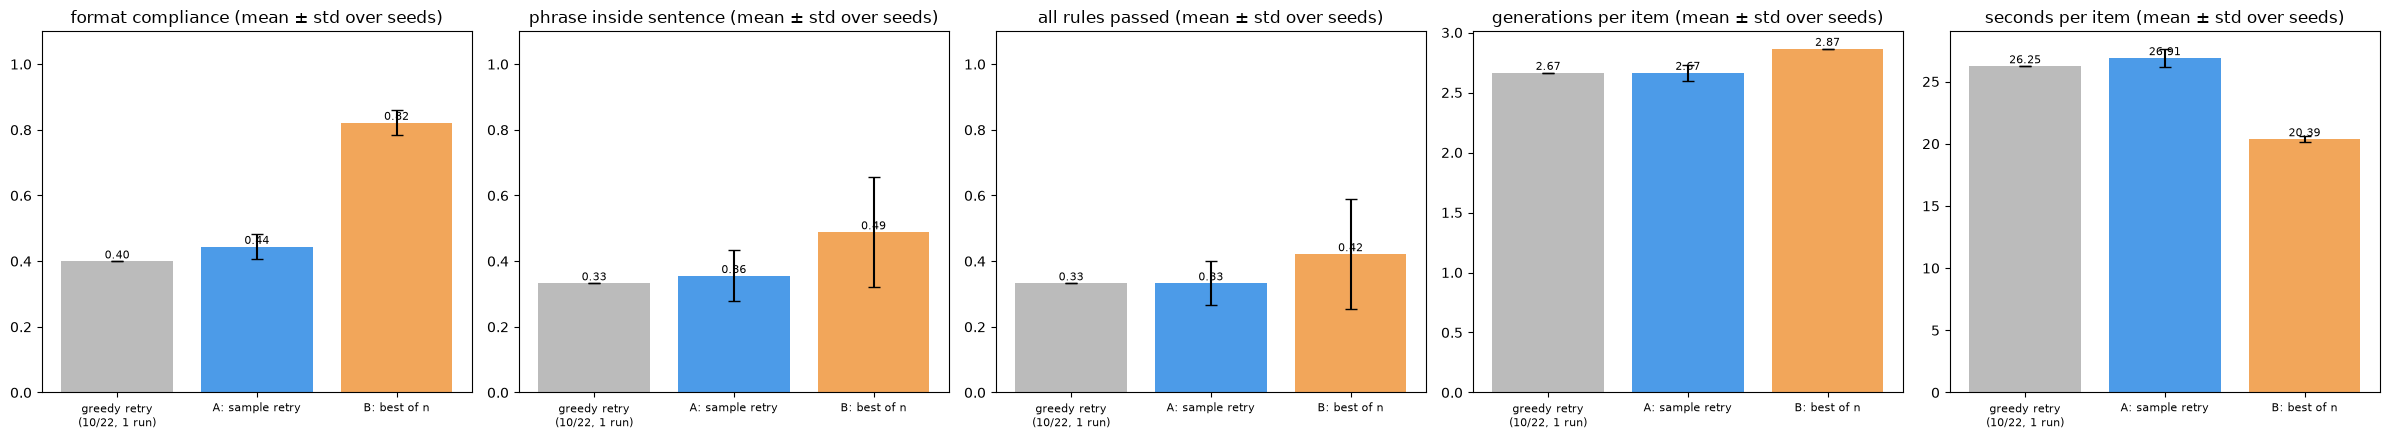

In [20]:
rg = pd.read_csv(REGEN_CSV, keep_default_na=False)
rg = rg[rg.error == ''].drop_duplicates(['method', 'seed', 'item'], keep='last')
print('sampling defaults:', rg.gen_cfg.iloc[0])
rows = []
for _, r in rg.iterrows():
    rows.append(dict(method=r.method, seed=int(r.seed), item=r['item'], n_gen=int(r.n_gen), sec=float(r.sec_total),
                     identical_repeats=int(r.identical_repeats), text=r.text, **score_must(r.text, r.game, 'retry')))
prev = mr[mr.method == 'retry']
for _, r in prev.iterrows():
    texts = json.loads(r.texts_all)
    rows.append(dict(method='greedy_retry (10/22)', seed=0, item=r['item'], n_gen=int(r.attempts), sec=float(r.sec_total),
                     identical_repeats=sum(texts[i] == texts[i - 1] for i in range(1, len(texts))), text=r.text,
                     **score_must(r.text, r.game, 'retry')))
rgs = pd.DataFrame(rows)
rgs['all_rules'] = rgs.format_ok & rgs.must_kept & rgs.integrated & (rgs.promo_violation == False) & (rgs.cliche == False)
REGEN_METHODS = ['greedy_retry (10/22)', 'retry_sample', 'best_of_n']
per_seed = rgs.groupby(['method', 'seed']).agg(format_ok=('format_ok', 'mean'), integrated=('integrated', 'mean'),
                                                all_rules=('all_rules', 'mean'), cliche=('cliche', 'mean'),
                                                n_gen=('n_gen', 'mean'), sec=('sec', 'mean'),
                                                identical_repeats=('identical_repeats', 'sum'))
summ_r = per_seed.groupby('method').agg(['mean', 'std']).reindex(REGEN_METHODS)
rgs.to_csv(OUT_DIR / 'regen_scored.csv', index=False, encoding='utf-8-sig')
summ_r.to_csv(OUT_DIR / 'regen_summary.csv', encoding='utf-8-sig')
display(per_seed.round(3))
display(summ_r.round(3))

cols = [('format_ok', 'format compliance'), ('integrated', 'phrase inside sentence'), ('all_rules', 'all rules passed'),
        ('n_gen', 'generations per item'), ('sec', 'seconds per item')]
fig, axes = plt.subplots(1, len(cols), figsize=(24, 4.5))
x = np.arange(len(REGEN_METHODS))
for ax, (col, title) in zip(axes, cols):
    m, s = summ_r[(col, 'mean')].values.astype(float), summ_r[(col, 'std')].values.astype(float)
    ax.bar(x, np.nan_to_num(m), yerr=np.nan_to_num(s), capsize=4, color=['#BBBBBB', '#4C9BE8', '#F2A65A'])
    for i, val in enumerate(m):
        ax.text(i, 0 if np.isnan(val) else val, 'n/a' if np.isnan(val) else f'{val:.2f}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x, ['greedy retry\n(10/22, 1 run)', 'A: sample retry', 'B: best of n'], fontsize=8)
    if col in ('format_ok', 'integrated', 'all_rules'):
        ax.set_ylim(0, 1.1)
    ax.set_title(f'{title} (mean ± std over seeds)')
plt.tight_layout()
plt.savefig(OUT_DIR / 'regen_compare.png', dpi=90)
plt.show()

### 재생성 방식별 문구 예시 (seed 0)

In [21]:
pd.set_option('display.max_colwidth', 400)
for g in GAMES:
    f0 = [p.name for gg, p in SAMPLES if gg == g][0]
    print(g, f0, '| 꼭 넣을 문구:', USER_POINTS[g]['must'])
    display(rgs[(rgs['item'] == f0) & (rgs.seed == 0)].set_index('method').reindex(REGEN_METHODS)[['all_rules', 'n_gen', 'text']])

nai gen_0729_screenshot.png | 꼭 넣을 문구: 11월 업데이트 기념 30% 할인


,all_rules,n_gen,text
method,,,
greedy_retry (10/22),True,1,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
retry_sample,True,1,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"
best_of_n,True,1,"{""store"": [""검은 고양이 기사가 빨간 모자를 쓰고 돌담 위에 앉아 있는, 동화책 같은 손그림 스타일의 게임입니다."", ""11월 업데이트로 신규 동료가 추가되어 더 풍성한 모험을 기대할 수 있어요.""], ""sns"": ""빨간 모자와 녹색 망토를 걸친 고양이 기사가 돌담 위에 앉아 있는, 11월 업데이트 기념 30% 할인 중인 어드벤처 게임입니다.""}"


x72 x72_scene_0497.png | 꼭 넣을 문구: 스팀 찜하기


,all_rules,n_gen,text
method,,,
greedy_retry (10/22),False,3,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요. 스팀 찜하기""}"
retry_sample,False,3,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요. 스팀 찜하기""}"
best_of_n,False,3,"{""store"": [""16비트 픽셀 아트로 그려진 던전에서 4명이 함께 펼쳐지는 협동 모험, 스팀 찜하기"", ""보물상자와 금화를 찾아보며, 마법사와 기사가 맞서는 몬스터들과의 대결을 즐겨보세요.""], ""sns"": ""스팀 찜하기, 4명이 함께 펼쳐지는 픽셀 던전에서 금화와 보물상자를 찾아보세요!""}"


kaykit kk_0223.png | 꼭 넣을 문구: 신규 영웅 로그 추가


,all_rules,n_gen,text
method,,,
greedy_retry (10/22),False,3,"{""store"": [""로우폴리 영웅이 휘두르는 지팡이와 마법의 흔들림, 신규 영웅 로그 추가로 더 풍부한 전투를 경험해 보세요."", ""5명의 영웅이 각각 다른 스킬로 전장을 휘감는, 친근하고 밝은 판타지 어드벤처입니다.""], ""sns"": ""파란색 마법사 모자와 지팡이를 휘두르는 로그가 등장해요. 신규 영웅 로그 추가로 전투의 재미가 배가됩니다!""}"
retry_sample,False,3,"{""store"": [""로우폴리 영웅이 휘두르는 지팡이와 마법의 흔들림, 신규 영웅 로그 추가로 더 풍부한 전투를 경험해 보세요."", ""5명의 영웅이 각각 다른 스킬로 전장을 휘감는, 친근하고 밝은 판타지 어드벤처입니다.""], ""sns"": ""파란색 마법사 모자와 지팡이를 휘두르는 로그가 등장해요. 신규 영웅 로그 추가로 전투의 재미가 배가됩니다!""}"
best_of_n,True,3,"{""store"": [""로우폴리 스타일의 판타지 어드벤처, 푸른 모자와 지팡이를 들고 전투를 시작하세요."", ""신규 영웅 로그 추가로 더 풍부한 전략과 즐거움을 경험해 보세요.""], ""sns"": ""신규 영웅 로그 추가로, 푸른 모자와 지팡이로 마법의 전투를 펼쳐보세요!""}"


## 규칙 통과율 개선 비교 (10/26)

위 "재생성 방식 비교"에서 확정한 (나) 후보 여러 개도 규칙 전부 통과가 0.42였다(`regen_scored.csv`, 45건 중 19건). 실패 원인은 꼭 넣을 문구가 문장 안에 들어가지 않음 23건, 형식(문장 수) 8건, 꼭 넣을 문구 빠짐 6건, 상투 구절 6건이다. 실패한 문장 안 넣기 23건의 상당수는 문구를 문장 끝에 쉼표로 붙인 경우였다(예: "…성문 아래에 앉아 있는 모습, 11월 업데이트 기념 30% 할인", "마법사와 기사가 함께하는 던전, 스팀 찜하기").

후보 세 가지를 같은 입력(사용자 입력 있음 15건)·같은 seed(0·1·2)로 비교한다.

| 후보 | 내용 | 최대 생성 횟수 |
|---|---|---|
| ① 끝에 붙이기 허용 | 검증의 `integrated`에서 "문구가 문장 맨 앞/맨 끝에 구두점으로 붙은 경우 실패" 조건만 뺀다. 문장 1개, 문구 외 한글 8자 이상 조건은 그대로 둔다. 생성 중 검증에도 같은 규칙을 써서 재생성 여부가 바뀐다 | 방식에 따름 |
| ② (나) 후보 4개 | (나)와 같고, 실패하면 샘플링 후보를 2개가 아니라 4개 만든다 | 5번 |
| ③ (나) + (가) | (나) 후보 2개 중 가장 나은 것이 그래도 실패하면, 그 글과 실패 이유를 모델에 보내 샘플링으로 한 번 더 고쳐 쓰게 한다(B 배너 문구에서 채택한 방식). 실패 항목이 줄었을 때만 바꾼다 | 4번 |

- 실행 조합: 지금 검증 × ②·③, 끝에 붙이기 허용 검증 × (나)·②·③ (5개). 지금 검증 × (나)는 위 `regen_compare.csv` 결과를 그대로 쓴다.
- 채점은 모든 조합을 지금 규칙과 끝에 붙이기 허용 규칙으로 각각 한다. 지표는 위와 같다(`score_must`: 형식, 꼭 넣을 문구, 문장 안 넣기, 판촉 표현, 상투 구절, 규칙 전부 통과).
- 후보 수 4는 근거 문서가 없는 탐색값이다(2개의 두 배). ③의 추가 1번은 B 배너 문구에서 쓴 (가) 재요청과 같은 문구·같은 샘플링 설정이다.
- 결과: `outputs/local_vlm/regen2_compare.csv`, `regen2_scored.csv`, `regen2_summary.csv`, `regen2_compare.png`
- 실행 순서: "설정" → "규칙 적용 지시문" → "꼭 넣을 문구 처리 방식 비교"의 첫 셀(`MUST_CSV = ...`) → "비교 지표와 그래프" → 이 섹션
- 예상 시간: 조합 5개 × seed 3개 × 15건. 위 (나)는 건당 평균 20.4초였고(`regen_summary.csv`), 후보 4개·추가 재요청은 이보다 길다 → 약 1~1.5시간(추정). 셀 출력에 조합별 실제 시간을 남긴다. 중간에 멈춰도 다시 실행하면 끝난 건은 건너뛴다.

In [ ]:
REGEN2_CSV = OUT_DIR / 'regen2_compare.csv'
REGEN_SEEDS = [0, 1, 2]
REGEN_TASKS = [t for t in MUST_TASKS if t['method'] == 'retry']

# ① 끝에 붙이기 허용: 위 VALIDATOR의 integrated에서 앞·뒤 구두점 붙임 조건만 뺌
_END_RULE = r'''    p = re.escape(must)
    if re.search(r'[.!?…,:;~\-—]\s*' + p + r'\s*[.!?…~]*\s*$', sns) or re.match(r'^\s*' + p + r'\s*[.!?…,:;~\-—]', sns):
        return False
'''
assert VALIDATOR.count(_END_RULE) == 1
VALIDATOR_RELAXED = VALIDATOR.replace(_END_RULE, '')
_ns = {}
exec(VALIDATOR_RELAXED, _ns)
integrated_relaxed = _ns['integrated']
assert not integrated('마법사와 기사가 함께하는 던전, 스팀 찜하기', '스팀 찜하기')
assert integrated_relaxed('마법사와 기사가 함께하는 던전, 스팀 찜하기', '스팀 찜하기')

# (방식, 검증, 후보 수)
RUNS2 = [('best_of_n', 'strict', 4), ('best_then_fb', 'strict', 2),
         ('best_of_n', 'relaxed', 2), ('best_of_n', 'relaxed', 4), ('best_then_fb', 'relaxed', 2)]


def run_label(method, rule, n):
    return f'{method}{n}|{rule}' if method == 'best_of_n' else f'{method}|{rule}'


CHILD_REGEN2 = r'''
import csv, json, os, sys, time
import torch
from PIL import Image
from transformers import AutoModelForImageTextToText, AutoProcessor

a = json.loads(sys.stdin.read())
exec(a['validator'])
FIELDS = ['method', 'seed', 'item', 'game', 'n_gen', 'sec_total', 'peak_vram_gb', 'load_sec', 'text', 'texts_all',
          'problems', 'identical_repeats', 'gen_cfg', 'error']
FB = '아래 문제를 고쳐서 다시 써줘. 나머지 규칙도 그대로 지키고, JSON 형식으로만 답해줘.\n'


def write(rec):
    new = not os.path.exists(a['out'])
    with open(a['out'], 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        if new:
            w.writeheader()
        w.writerow({k: rec.get(k, '') for k in FIELDS})


t0 = time.perf_counter()
proc = AutoProcessor.from_pretrained(a['repo'])
model = AutoModelForImageTextToText.from_pretrained(a['repo'], dtype=torch.bfloat16, device_map='cuda').eval()
load_sec = round(time.perf_counter() - t0, 1)
gc = model.generation_config
GEN_CFG = json.dumps(dict(temperature=gc.temperature, top_p=gc.top_p, top_k=gc.top_k,
                          repetition_penalty=getattr(gc, 'repetition_penalty', None)))
print('LOADED', load_sec, 's | sampling defaults', GEN_CFG, flush=True)


def gen(messages, sample, n=1):
    inputs = proc.apply_chat_template(messages, add_generation_prompt=True, tokenize=True, return_dict=True,
                                      return_tensors='pt').to(model.device)
    kw = dict(do_sample=True, num_return_sequences=n) if sample else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=a['max_new_tokens'], **kw)
    n_in = inputs['input_ids'].shape[1]
    return proc.batch_decode(out[:, n_in:], skip_special_tokens=True, clean_up_tokenization_spaces=False)


def probs_of(text, t):
    return check(text, t['must'], t['allowed'], a['banned_promo'], a['banned_cliche'], True)


for t in a['tasks']:
    rec = dict(method=a['label'], seed=a['seed'], item=t['item'], game=t['game'], load_sec=load_sec, gen_cfg=GEN_CFG)
    try:
        torch.manual_seed(a['seed'])
        messages = [{'role': 'system', 'content': [{'type': 'text', 'text': t['system']}]},
                    {'role': 'user', 'content': [{'type': 'image', 'image': Image.open(t['image']).convert('RGB')},
                                                 {'type': 'text', 'text': t['prompt']}]}]
        torch.cuda.reset_peak_memory_stats()
        t1 = time.perf_counter()
        texts = gen(messages, sample=False)
        final, probs = texts[0], probs_of(texts[0], t)
        if probs:
            # (나): 실패 이유 없이 같은 입력으로 샘플링 후보 n개 → 실패 항목이 가장 적은 후보
            cands = gen(messages, sample=True, n=a['n_cand'])
            texts += cands
            n_bad, _, best = min((len(probs_of(c, t)), i, c) for i, c in enumerate(cands))
            if n_bad < len(probs):
                final, probs = best, probs_of(best, t)
            if probs and a['method'] == 'best_then_fb':
                # (가): 가장 나은 글과 실패 이유를 보내 샘플링으로 한 번 더 고쳐 쓰게 함
                m2 = messages + [{'role': 'assistant', 'content': [{'type': 'text', 'text': final}]},
                                 {'role': 'user', 'content': [{'type': 'text', 'text': FB + '\n'.join('- ' + x for x in probs)}]}]
                fix = gen(m2, sample=True)[0]
                texts.append(fix)
                fp = probs_of(fix, t)
                if len(fp) < len(probs):
                    final, probs = fix, fp
        rec.update(n_gen=len(texts), sec_total=round(time.perf_counter() - t1, 2),
                   peak_vram_gb=round(torch.cuda.max_memory_allocated() / 1024**3, 2), text=final,
                   texts_all=json.dumps(texts, ensure_ascii=False), problems=json.dumps(probs, ensure_ascii=False),
                   identical_repeats=sum(texts[i] == texts[i - 1] for i in range(1, len(texts))))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:500]
    write(rec)
    print(a['label'], a['seed'], t['item'], rec.get('n_gen'), rec.get('sec_total'), 's', rec.get('error', '')[:120], flush=True)
'''

done = set()
if REGEN2_CSV.exists():
    _r = pd.read_csv(REGEN2_CSV, keep_default_na=False, dtype=str)
    _r = _r[_r.error == '']
    done = set(zip(_r.method, _r.seed.astype(int), _r['item']))
run_time = {}
for method, rule, n in RUNS2:
    label = run_label(method, rule, n)
    for seed in REGEN_SEEDS:
        todo = [t for t in REGEN_TASKS if (label, seed, t['item']) not in done]
        if not todo:
            print(label, seed, '이미 완료 → 건너뜀')
            continue
        t_run = time.perf_counter()
        arg = json.dumps(dict(repo=QWEN_REPO, method=method, label=label, seed=seed, n_cand=n, max_new_tokens=MAX_NEW_TOKENS,
                              validator=VALIDATOR if rule == 'strict' else VALIDATOR_RELAXED, banned_promo=BANNED_PROMO,
                              banned_cliche=BANNED_CLICHE, out=str(REGEN2_CSV.resolve()), tasks=todo))
        p = subprocess.run([sys.executable, '-c', CHILD_REGEN2], input=arg, capture_output=True, text=True, encoding='utf-8',
                           errors='replace', env={**os.environ, 'PYTHONIOENCODING': 'utf-8'})
        run_time[(label, seed)] = round(time.perf_counter() - t_run, 1)
        print(p.stdout[-800:])
        if p.returncode != 0:
            print(p.stderr[-2000:])
        print(f'{label} seed {seed}: {run_time[(label, seed)]}초 (모델 로드 포함)', flush=True)

### 규칙 통과율 개선 비교 지표와 그래프

In [ ]:
def score_relaxed(text, g):
    s = score_must(text, g, 'retry')
    d = parse_json(text)
    s['integrated'] = bool(d and isinstance(d.get('sns'), str) and integrated_relaxed(d['sns'], USER_POINTS[g]['must']))
    return s


frames = []
prev = pd.read_csv(REGEN_CSV, keep_default_na=False)
prev = prev[(prev.error == '') & (prev.method == 'best_of_n')].assign(method='best_of_n2|strict')
new = pd.read_csv(REGEN2_CSV, keep_default_na=False)
new = new[new.error == '']
for src in [prev, new]:
    frames.append(src.drop_duplicates(['method', 'seed', 'item'], keep='last'))
r2 = pd.concat(frames, ignore_index=True)
rows = []
for _, r in r2.iterrows():
    base = dict(method=r.method, seed=int(r.seed), item=r['item'], game=r.game, n_gen=int(r.n_gen), sec=float(r.sec_total),
                text=r.text)
    for score_rule, fn in [('strict', lambda t, g: score_must(t, g, 'retry')), ('relaxed', score_relaxed)]:
        rows.append(dict(base, score_rule=score_rule, **fn(r.text, r.game)))
r2s = pd.DataFrame(rows)
r2s['all_rules'] = r2s.format_ok & r2s.must_kept & r2s.integrated & (r2s.promo_violation == False) & (r2s.cliche == False)
R2_METHODS = ['best_of_n2|strict', 'best_of_n4|strict', 'best_then_fb|strict',
              'best_of_n2|relaxed', 'best_of_n4|relaxed', 'best_then_fb|relaxed']
per_seed2 = r2s.groupby(['score_rule', 'method', 'seed']).agg(
    format_ok=('format_ok', 'mean'), must_kept=('must_kept', 'mean'), integrated=('integrated', 'mean'),
    cliche=('cliche', 'mean'), all_rules=('all_rules', 'mean'), n_gen=('n_gen', 'mean'), sec=('sec', 'mean'))
summ2 = per_seed2.groupby(['score_rule', 'method']).agg(['mean', 'std'])
r2s.to_csv(OUT_DIR / 'regen2_scored.csv', index=False, encoding='utf-8-sig')
summ2.to_csv(OUT_DIR / 'regen2_summary.csv', encoding='utf-8-sig')
print('조합별 건수:', r2.groupby('method').size().to_dict())
display(summ2.round(3))
print('게임별 규칙 전부 통과 (seed 평균)')
display(r2s.groupby(['score_rule', 'method', 'game']).all_rules.mean().unstack().round(3))

methods = [m for m in R2_METHODS if m in set(r2s.method)]
fig, axes = plt.subplots(1, 4, figsize=(26, 4.8))
x = np.arange(len(methods))
for k, (rule, color) in enumerate([('strict', '#4C78A8'), ('relaxed', '#F58518')]):
    s = summ2.loc[rule].reindex(methods)
    axes[0].bar(x + (k - 0.5) * 0.38, s[('all_rules', 'mean')], 0.38, yerr=s[('all_rules', 'std')].fillna(0), capsize=3,
                color=color, label=f'scored with {rule} rule')
    axes[1].bar(x + (k - 0.5) * 0.38, s[('integrated', 'mean')], 0.38, yerr=s[('integrated', 'std')].fillna(0), capsize=3,
                color=color, label=f'scored with {rule} rule')
s = summ2.loc['strict'].reindex(methods)
axes[2].bar(x, s[('n_gen', 'mean')], color='#54A24B')
axes[3].bar(x, s[('sec', 'mean')], yerr=s[('sec', 'std')].fillna(0), capsize=3, color='#B279A2')
for ax, title in zip(axes, ['all rules passed (mean ± std over seeds)', 'phrase inside sentence', 'generations per item',
                            'seconds per item']):
    ax.set_xticks(x, [m.replace('|', '\n') for m in methods], fontsize=8)
    ax.set_title(title)
for ax in axes[:2]:
    ax.set_ylim(0, 1.1)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / 'regen2_compare.png', dpi=90)
plt.show()

In [ ]:
pd.set_option('display.max_colwidth', 400)
for g in GAMES:
    f0 = [p.name for gg, p in SAMPLES if gg == g][0]
    print(g, f0, '| 꼭 넣을 문구:', USER_POINTS[g]['must'])
    ex = r2s[(r2s['item'] == f0) & (r2s.seed == 0)].pivot_table(index='method', columns='score_rule', values='all_rules',
                                                                 aggfunc='first')
    ex['text'] = r2s[(r2s['item'] == f0) & (r2s.seed == 0) & (r2s.score_rule == 'strict')].set_index('method').text
    display(ex.reindex(methods))